# Apple Stock Market Regime Analysis Using Unsupervised Machine Learning

## Introduction

Capital markets operate in different regimes, encompassing both periods of stability and times of intense activity (booms or falls). Mapping these patterns helps explain the evolution of stock market conditions over time. This project investigates approximately ten years of historical Apple data obtained via Yahoo Finance, analysing variables such as closing price, volume, returns, daily maximum and minimum swings, and volatility. Due to the absence of pre-established labels for economic cycles in the dataset, unsupervised clustering techniques are used.

## Project Objectives

To prepare and explore ten years of Apple stock market data.

To identify interpretable market regimes using K-Means and DBSCAN.

To compare the clustering models using the Silhouette Score, Davies–Bouldin Index and cluster interpretability.

To investigate trend, stationarity and seasonality in Apple’s adjusted closing price.

To develop and compare Naive, ARIMA and SARIMA forecasts.

To critically evaluate the strengths and limitations of the models

## Research Questions

Can unsupervised machine learning identify distinct market regimes in Apple stock trading data?

What characteristics differentiate stable, positive high-activity and negative high-activity trading days?

Which clustering model provides the most meaningful representation of the trading patterns in the dataset?

How are the identified market regimes distributed throughout the analysed period?

How accurately can ARIMA and SARIMA forecast Apple’s adjusted closing price compared with a Naive Forecast?

In [1]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sklearn.preprocessing as preproc
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [3]:
import yfinance as yf

ticker_symbol = "AAPL"

# Download historical data (adjust the period as needed, e.g., '1mo', '1y', 'max')
data = yf.download(
    ticker_symbol,
    start="2016-10-08",
    end="2026-10-09",
    interval="1d",
    auto_adjust=False,
    multi_level_index=False,
    progress=False
)


data = data.reset_index()

data.columns.name = None

data.to_csv('AAPL_historical_data.csv')

print("Data downloaded and saved as AAPL_historical_data.csv")

Data downloaded and saved as AAPL_historical_data.csv


In [4]:
data.to_csv(
    "AAPL_historical_data.csv",
    index=False
)

print("Dataset saved successfully.")
print("Dataset shape:", data.shape)
print("Columns:", data.columns.tolist())

Dataset saved successfully.
Dataset shape: (2513, 7)
Columns: ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


In [5]:
data.head()

,Date,Adj Close,Close,High,Low,Open,Volume
0,2016-10-10,26.538967,29.012501,29.187500,28.680000,28.754999,144944000
1,2016-10-11,26.596134,29.075001,29.672501,29.049999,29.424999,256164000
2,2016-10-12,26.833969,29.334999,29.495001,29.187500,29.337500,150347200
3,2016-10-13,26.751650,29.245001,29.360001,28.930000,29.197500,140769600
4,2016-10-14,26.900293,29.407499,29.542500,29.282499,29.469999,142608800


In [6]:
# Preserve an unchanged copy of the downloaded dataset
data_original = data.copy()

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2513 entries, 0 to 2512
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       2513 non-null   datetime64[ns]
 1   Adj Close  2513 non-null   float64       
 2   Close      2513 non-null   float64       
 3   High       2513 non-null   float64       
 4   Low        2513 non-null   float64       
 5   Open       2513 non-null   float64       
 6   Volume     2513 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 137.6 KB


In [8]:
data.describe()

,Date,Adj Close,Close,High,Low,Open,Volume
count,2513,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000,2.513000e+03
mean,2021-10-07 13:46:17.715877376,134.567372,136.958811,138.329123,135.448595,136.820037,9.316546e+07
min,2016-10-10 00:00:00,24.298479,26.427500,26.920000,26.020000,26.642500,1.791060e+07
25%,2019-04-10 00:00:00,48.759979,51.117500,51.527500,50.672501,51.070000,5.451150e+07
50%,2021-10-06 00:00:00,138.752594,142.059998,143.520004,139.899994,142.059998,8.107720e+07
75%,2024-04-08 00:00:00,189.252686,191.559998,192.979996,189.910004,191.440002,1.136056e+08
max,2026-10-08 00:00:00,341.070007,341.070007,345.339996,338.750000,341.079987,4.479400e+08
std,NaN,82.203312,81.659155,82.451299,80.773683,81.555785,5.361629e+07


In [9]:
data.isnull().sum()

Date         0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

In [10]:
data.duplicated().sum()

np.int64(0)

In [11]:
duplicate_dates = data["Date"].duplicated().sum()

print("Number of duplicated dates:", duplicate_dates)

Number of duplicated dates: 0


This graph shows how Apple’s adjusted share price changed over time. Adj Close was selected because it accounts for changes such as dividends and stock splits.

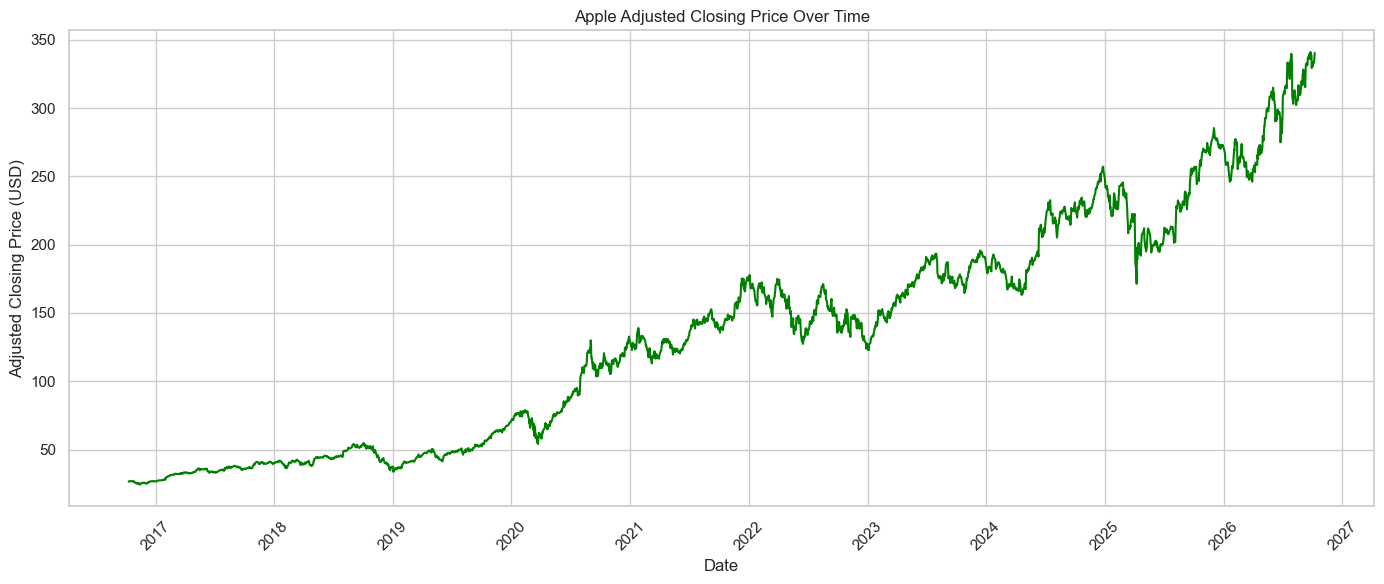

In [12]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(14, 6))

plt.plot(
    data["Date"],
    data["Adj Close"],
    color="green",
    linewidth=1.5
)

plt.title("Apple Adjusted Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The graph shows a strong upward trend in Apple’s adjusted closing price during the ten-year period. The price increased from approximately USD 25 to more than USD 340, although several temporary declines and periods of greater price variation can also be observed. This trend suggests that the original price series may not be stationary, but this will be confirmed later using the Augmented Dickey-Fuller test

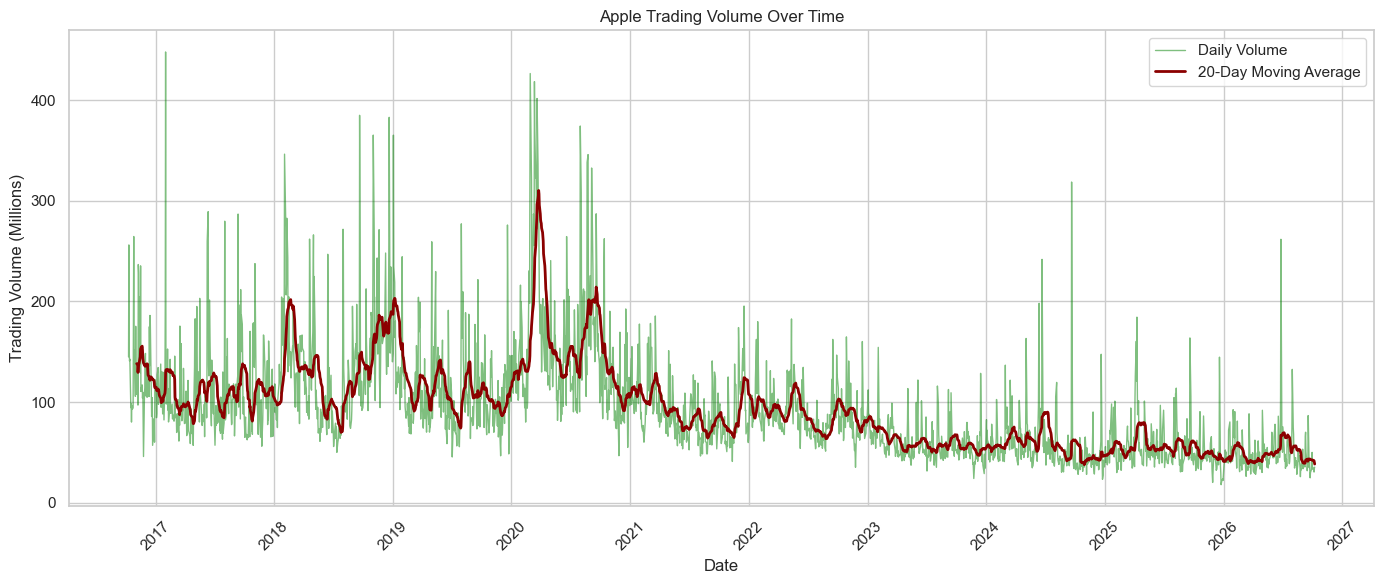

In [13]:
# Convert Volume to millions for easier interpretation
volume_millions = data["Volume"] / 1_000_000

# Calculate the 20-day moving average
volume_ma20 = volume_millions.rolling(window=20).mean()

plt.figure(figsize=(14, 6))

plt.plot(
    data["Date"],
    volume_millions,
    color="green",
    alpha=0.5,
    linewidth=1,
    label="Daily Volume"
)

plt.plot(
    data["Date"],
    volume_ma20,
    color="darkred",
    linewidth=2,
    label="20-Day Moving Average"
)

plt.title("Apple Trading Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Trading Volume (Millions)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The graph shows considerable variation in Apple’s daily trading volume. The highest volumes were mainly observed between 2017 and 2020, followed by a general decline in the 20-day moving average. Some isolated peaks can still be observed in the most recent years, indicating days of unusually high market activity.

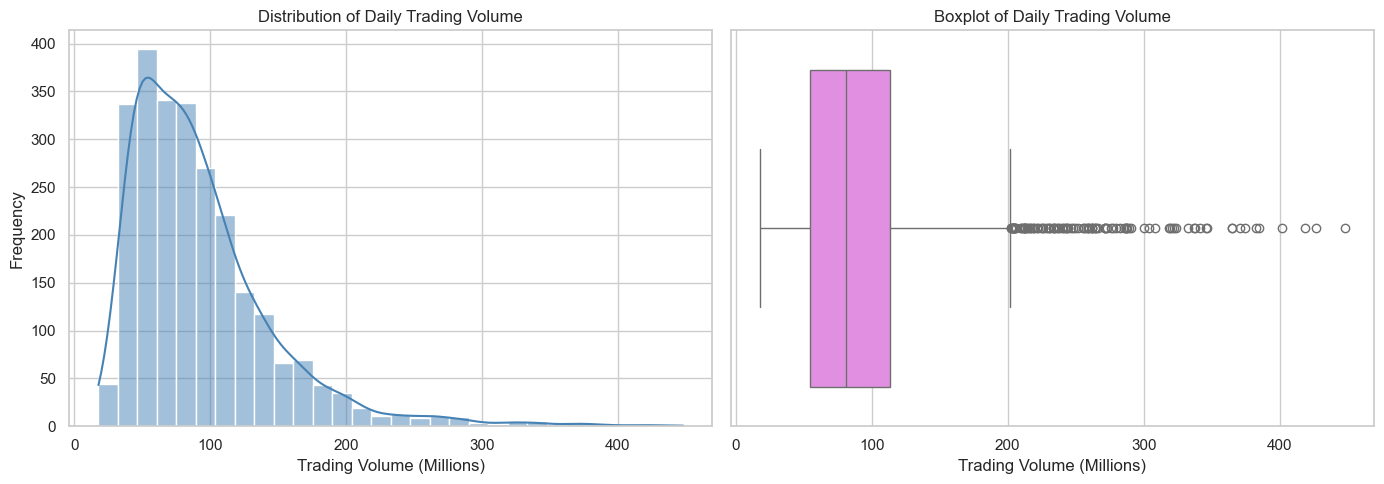

In [14]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Histogram
sns.histplot(
    volume_millions,
    bins=30,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Distribution of Daily Trading Volume")
axes[0].set_xlabel("Trading Volume (Millions)")
axes[0].set_ylabel("Frequency")

# Boxplot
sns.boxplot(
    x=volume_millions,
    color="violet",
    ax=axes[1]
)

axes[1].set_title("Boxplot of Daily Trading Volume")
axes[1].set_xlabel("Trading Volume (Millions)")

plt.tight_layout()
plt.show()

The trading volume has a positively skewed distribution, with most observations concentrated at lower and moderate values. The boxplot identified several unusually high volumes above approximately 200 million shares. These observations were retained because they may represent genuine periods of increased market activity rather than data errors

<Axes: >

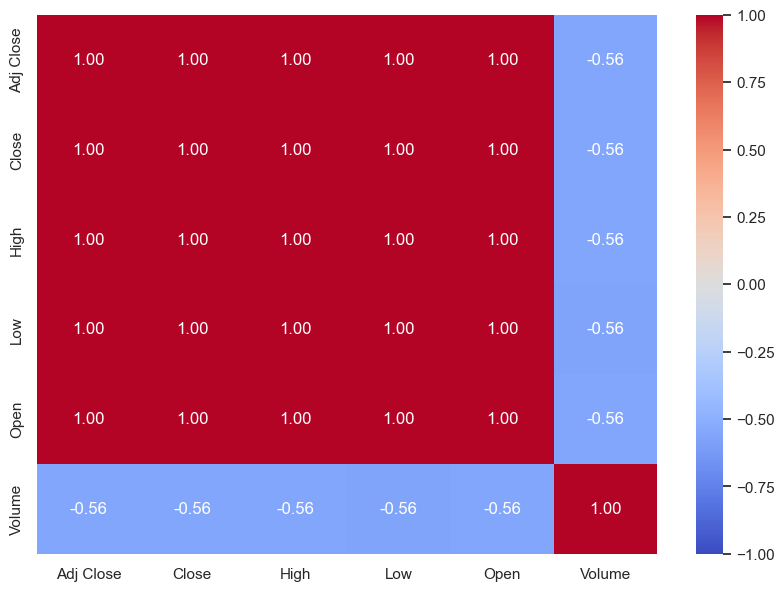

In [15]:
#Correlations 

numerical_columns = [
    "Adj Close",
    "Close",
    "High",
    "Low",
    "Open",
    "Volume"
]

correlation_matrix = data[numerical_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

The correlation matrix analysis shows a very strong positive correlation between the adjusted closing, opening, high, and low prices. This is expected, as these variables indicate different price measures of the same stock and generally move together. Volume shows a moderate negative correlation of approximately -0.56 with the price variables. However, correlation does not necessarily indicate causation.

Experimentation with new variables created to represent the daily behavior of Apple's stock. These variables measure daily return, intraday price range, price change between open and close, volume change, and 20-day rolling volatility. They provide more relevant information for cluster analysis than using only the original price variables.

In [16]:

data_features = data.copy()


data_features["Daily_Return"] = data_features["Adj Close"].pct_change() * 100


data_features["Intraday_Range"] = (
    (data_features["High"] - data_features["Low"])
    / data_features["Open"]
) * 100


data_features["Open_Close_Change"] = (
    (data_features["Close"] - data_features["Open"])
    / data_features["Open"]
) * 100

data_features["Volume_Change"] = data_features["Volume"].pct_change() * 100


data_features["Rolling_Volatility"] = (
    data_features["Daily_Return"].rolling(window=20).std()
)

data_features.head(25)

,Date,Adj Close,Close,High,Low,Open,Volume,Daily_Return,Intraday_Range,Open_Close_Change,Volume_Change,Rolling_Volatility
0,2016-10-10,26.538967,29.012501,29.187500,28.680000,28.754999,144944000,NaN,1.764909,0.895502,NaN,NaN
1,2016-10-11,26.596134,29.075001,29.672501,29.049999,29.424999,256164000,0.215408,2.115553,-1.189460,76.733083,NaN
2,2016-10-12,26.833969,29.334999,29.495001,29.187500,29.337500,150347200,0.894246,1.048149,-0.008523,-41.308224,NaN
3,2016-10-13,26.751650,29.245001,29.360001,28.930000,29.197500,140769600,-0.306773,1.472730,0.162687,-6.370321,NaN
4,2016-10-14,26.900293,29.407499,29.542500,29.282499,29.469999,142608800,0.555642,0.882254,-0.212080,1.306532,NaN
5,2016-10-17,26.882000,29.387501,29.459999,29.195000,29.332500,94499600,-0.068004,0.903433,0.187506,-33.735085,NaN
6,2016-10-18,26.863701,29.367500,29.552500,29.362499,29.545000,98214000,-0.068072,0.643089,-0.600778,3.930599,NaN
7,2016-10-19,26.783657,29.280001,29.440001,28.450001,29.312500,80138400,-0.297963,3.377398,-0.110872,-18.404301,NaN
8,2016-10-20,26.769943,29.264999,29.344999,29.082500,29.215000,96503200,-0.051202,0.898507,0.171142,20.420672,NaN
9,2016-10-21,26.664749,29.150000,29.227501,29.070000,29.202499,92770800,-0.392956,0.539342,-0.179778,-3.867644,NaN


In [17]:
print("Number of rows:", data_features.shape[0])
print("Number of columns:", data_features.shape[1])
print("\nColumn names:")
print(data_features.columns.tolist())

print("\nMissing values:")
print(data_features.isnull().sum())

Number of rows: 2513
Number of columns: 12

Column names:
['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'Intraday_Range', 'Open_Close_Change', 'Volume_Change', 'Rolling_Volatility']

Missing values:
Date                   0
Adj Close              0
Close                  0
High                   0
Low                    0
Open                   0
Volume                 0
Daily_Return           1
Intraday_Range         0
Open_Close_Change      0
Volume_Change          1
Rolling_Volatility    20
dtype: int64


In [18]:
missing_rows = data_features[
    data_features[
        [
            "Daily_Return",
            "Volume_Change",
            "Rolling_Volatility"
        ]
    ].isnull().any(axis=1)
]

print("Number of rows with missing values:", len(missing_rows))

missing_rows[
    [
        "Date",
        "Adj Close",
        "Volume",
        "Daily_Return",
        "Volume_Change",
        "Rolling_Volatility"
    ]
    ]

Number of rows with missing values: 20


,Date,Adj Close,Volume,Daily_Return,Volume_Change,Rolling_Volatility
0,2016-10-10,26.538967,144944000,NaN,NaN,NaN
1,2016-10-11,26.596134,256164000,0.215408,76.733083,NaN
2,2016-10-12,26.833969,150347200,0.894246,-41.308224,NaN
3,2016-10-13,26.751650,140769600,-0.306773,-6.370321,NaN
4,2016-10-14,26.900293,142608800,0.555642,1.306532,NaN
5,2016-10-17,26.882000,94499600,-0.068004,-33.735085,NaN
6,2016-10-18,26.863701,98214000,-0.068072,3.930599,NaN
7,2016-10-19,26.783657,80138400,-0.297963,-18.404301,NaN
8,2016-10-20,26.769943,96503200,-0.051202,20.420672,NaN
9,2016-10-21,26.664749,92770800,-0.392956,-3.867644,NaN


In [19]:
missing_rows[
    [
        "Daily_Return",
        "Volume_Change",
        "Rolling_Volatility"
    ]
].isnull()


,Daily_Return,Volume_Change,Rolling_Volatility
0,True,True,True
1,False,False,True
2,False,False,True
3,False,False,True
4,False,False,True
5,False,False,True
6,False,False,True
7,False,False,True
8,False,False,True
9,False,False,True


In [20]:
missing_rows[
    [
        "Adj Close",
        "Volume",
        "Daily_Return",
        "Intraday_Range",
        "Open_Close_Change",
        "Volume_Change"
    ]
].describe()

,Adj Close,Volume,Daily_Return,Intraday_Range,Open_Close_Change,Volume_Change
count,20.000000,2.000000e+01,19.000000,20.000000,20.000000,19.000000
mean,26.369771,1.381624e+08,-0.306854,1.439467,-0.118717,5.986895
std,0.619864,5.132222e+07,0.832116,0.762450,0.683002,41.031035
min,25.017933,8.013840e+07,-2.249469,0.539342,-1.736296,-47.739596
25%,25.995836,9.778630e+07,-0.782664,0.896433,-0.309254,-24.312803
50%,26.630442,1.307980e+08,-0.158251,1.260440,-0.052656,1.306532
75%,26.841402,1.506221e+08,0.152560,1.816633,0.204217,17.458801
max,27.042072,2.645368e+08,0.900500,3.377398,1.119761,104.467536


In [21]:
feature_columns = [
    "Daily_Return",
    "Intraday_Range",
    "Open_Close_Change",
    "Volume_Change",
    "Rolling_Volatility"
]


data_features[feature_columns] = (
    data_features[feature_columns]
    .replace([np.inf, -np.inf], np.nan)
)


clustering_data = (
    data_features
    .dropna(subset=feature_columns)
    .copy()
)


clustering_data.reset_index(drop=True, inplace=True)

print("Rows before cleaning:", len(data_features))
print("Rows after cleaning:", len(clustering_data))
print("Columns after cleaning:", clustering_data.shape[1])

print("\nMissing values in clustering features:")
print(clustering_data[feature_columns].isnull().sum())

print("\nInfinite values:")
print(np.isinf(clustering_data[feature_columns]).sum())

Rows before cleaning: 2513
Rows after cleaning: 2493
Columns after cleaning: 12

Missing values in clustering features:
Daily_Return          0
Intraday_Range        0
Open_Close_Change     0
Volume_Change         0
Rolling_Volatility    0
dtype: int64

Infinite values:
Daily_Return          0
Intraday_Range        0
Open_Close_Change     0
Volume_Change         0
Rolling_Volatility    0
dtype: int64


A total of 20 observations, representing approximately 0.80% of the dataset, contained missing values because insufficient historical data were available to calculate the 20-day rolling volatility. These observations were removed only from the clustering dataset. The original time-series dataset was preserved, while a cleaned dataset containing 2,493 observations was created for clustering.

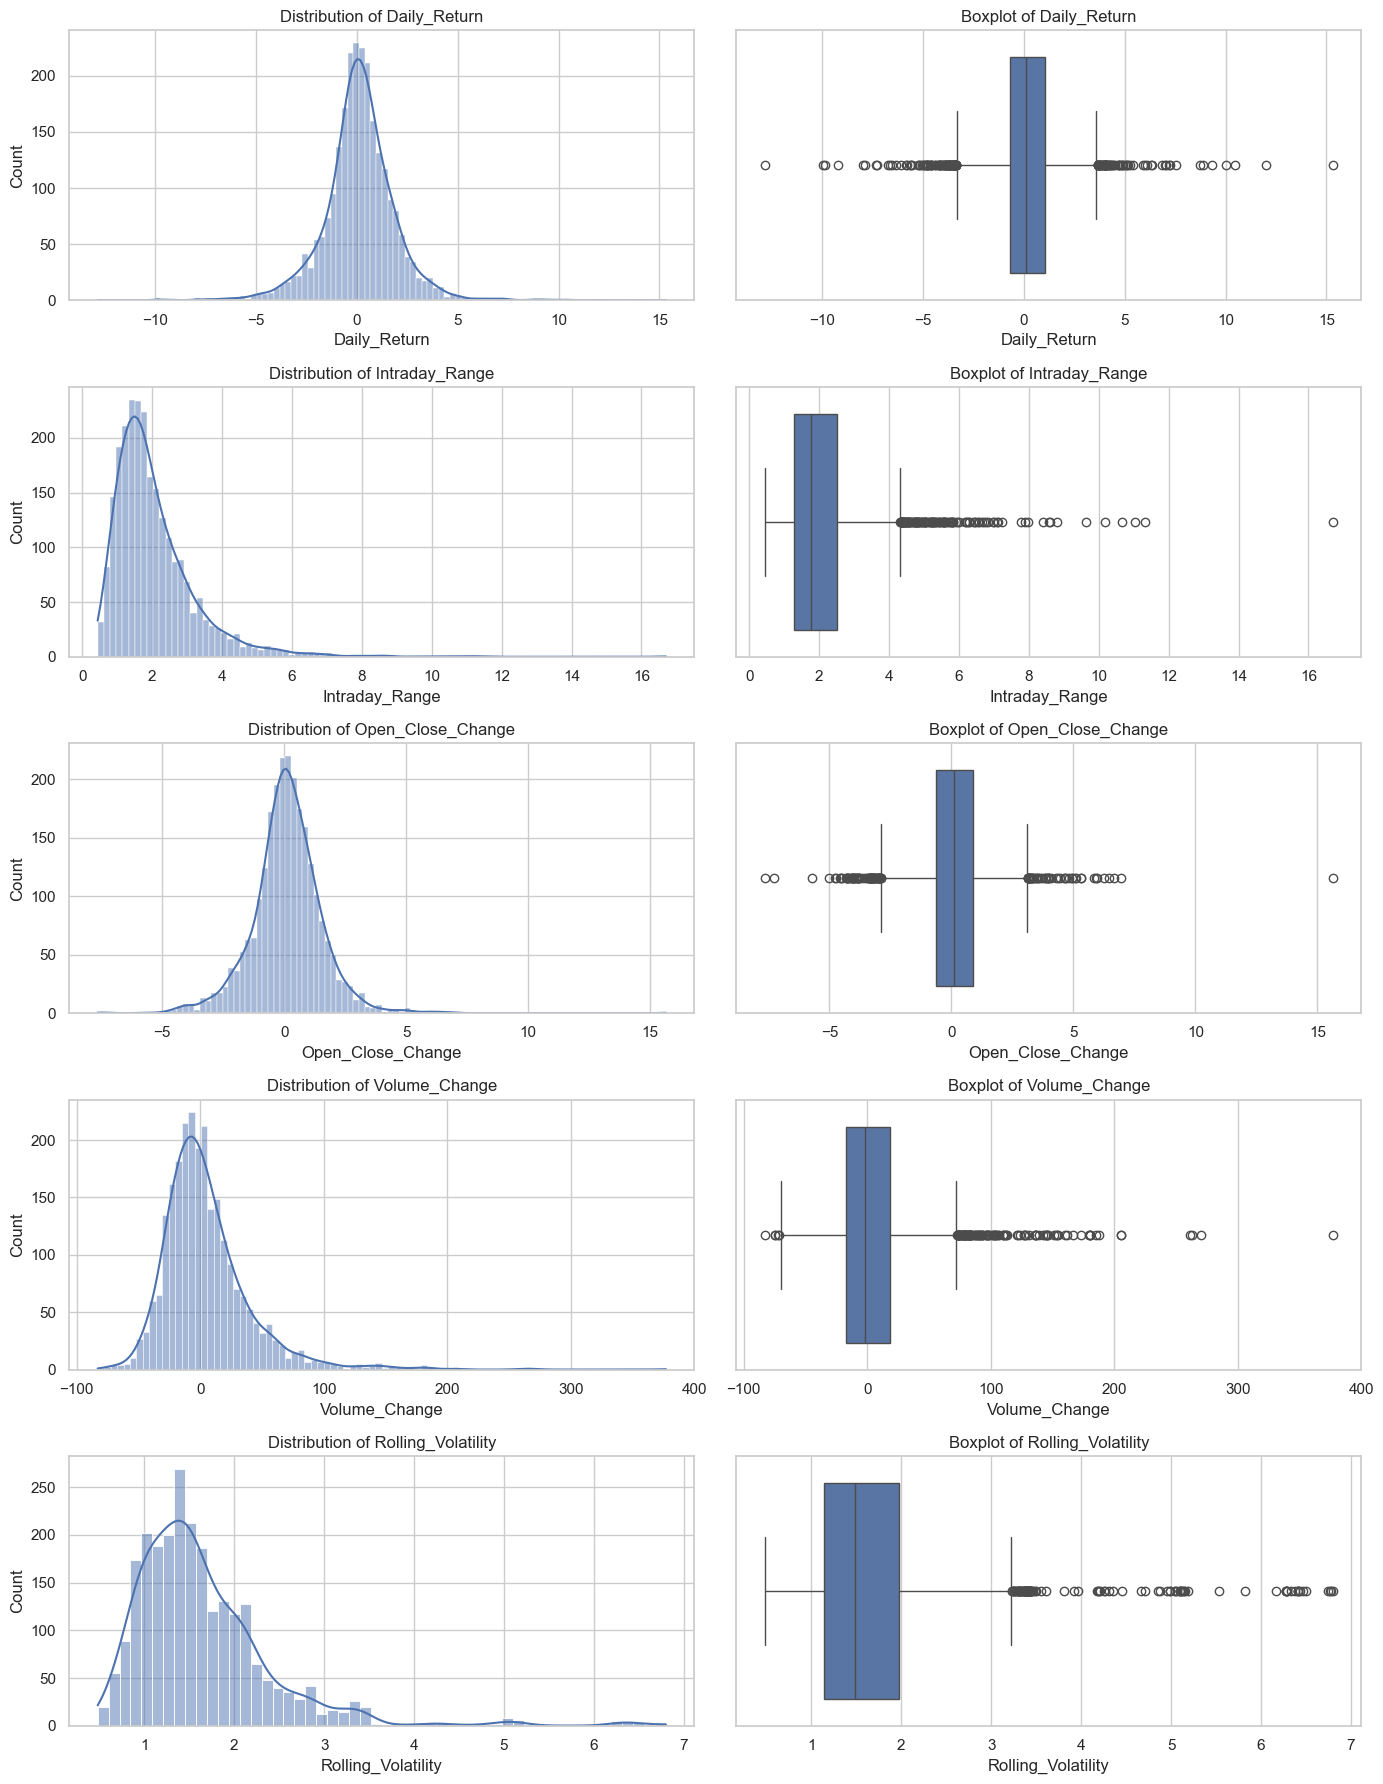

In [22]:
fig, axes = plt.subplots(
    nrows=len(feature_columns),
    ncols=2,
    figsize=(14, 18)
)

for i, column in enumerate(feature_columns):

    sns.histplot(
        clustering_data[column],
        kde=True,
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"Distribution of {column}")

    sns.boxplot(
        x=clustering_data[column],
        ax=axes[i, 1]
    )
    axes[i, 1].set_title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

The distributions and boxplots revealed several extreme observations. Daily return and opening-to-closing change were centred near zero but contained outliers on both sides. Intraday range, volume change and rolling volatility were positively skewed and contained high-value outliers. These observations were retained because they may represent genuine periods of unusual market activity. RobustScaler was selected because it is less sensitive to extreme values than StandardScaler

In [23]:
distribution_summary = clustering_data[feature_columns].agg(
    ["mean", "median", "std", "min", "max", "skew"]
).T

distribution_summary

,mean,median,std,min,max,skew
Daily_Return,0.121682,0.117671,1.840450,-12.864725,15.328850,0.118179
Intraday_Range,2.061132,1.765954,1.214877,0.439312,16.702531,2.753386
Open_Close_Change,0.108823,0.102470,1.435701,-7.648634,15.644088,0.464071
Volume_Change,5.036001,-1.707699,36.139792,-83.009283,377.199306,2.224211
Rolling_Volatility,1.659050,1.486466,0.812306,0.481534,6.800411,2.479357


In [24]:
import pandas as pd
from sklearn.preprocessing import RobustScaler

X = clustering_data[feature_columns].copy()


robust_scaler = RobustScaler()
X_scaled = robust_scaler.fit_transform(X)


scaled_features = pd.DataFrame(
    X_scaled,
    columns=feature_columns,
    index=clustering_data.index
)

print("Scaled dataset shape:", scaled_features.shape)
scaled_features.describe().T

Scaled dataset shape: (2493, 5)


,count,mean,std,min,25%,50%,75%,max
Daily_Return,2493.0,0.002307,1.058285,-7.465065,-0.481020,0.0,0.518980,8.746648
Intraday_Range,2493.0,0.244255,1.005294,-1.097778,-0.395816,0.0,0.604184,12.359809
Open_Close_Change,2493.0,0.004244,0.959250,-5.178825,-0.481595,0.0,0.518405,10.383982
Volume_Change,2493.0,0.188586,1.010640,-2.273577,-0.434149,0.0,0.565851,10.596032
Rolling_Volatility,2493.0,0.206701,0.972886,-1.203590,-0.417919,0.0,0.582081,6.364425


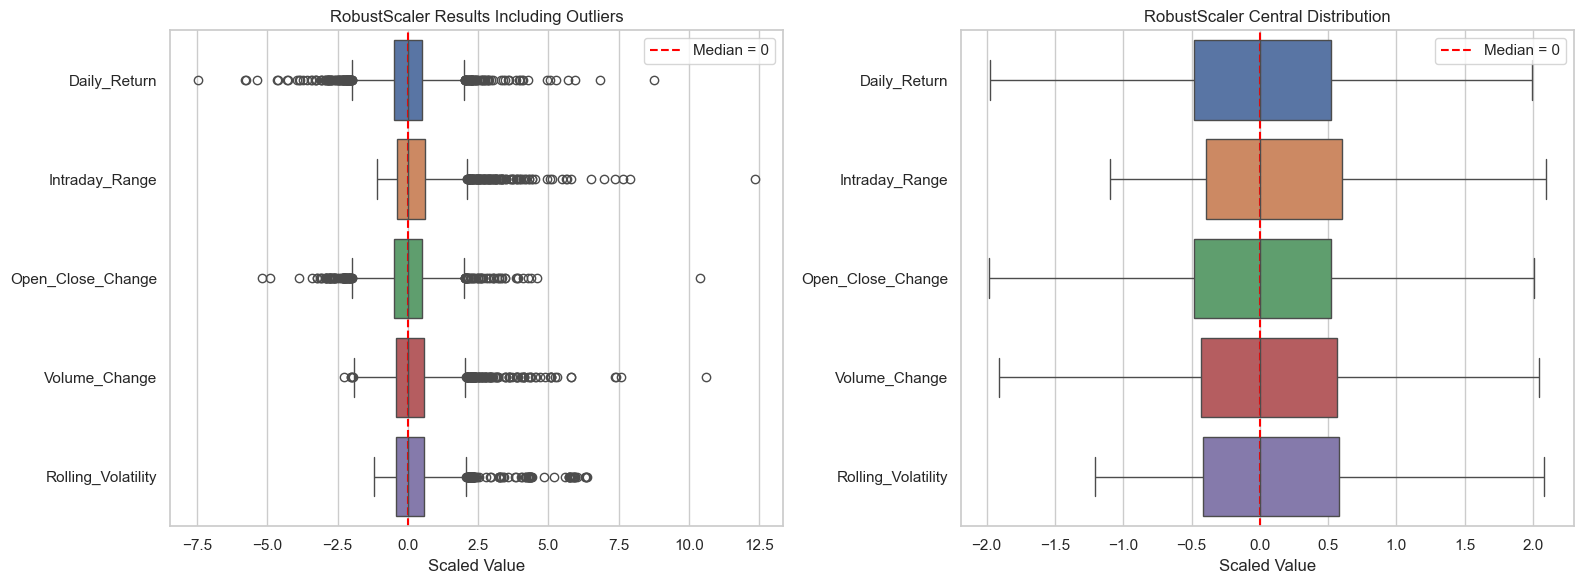

In [25]:
Fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(
    data=scaled_features,
    orient="h",
    ax=axes[0],
    showfliers=True
)

axes[0].axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Median = 0"
)

axes[0].set_title("RobustScaler Results Including Outliers")
axes[0].set_xlabel("Scaled Value")
axes[0].legend()


sns.boxplot(
    data=scaled_features,
    orient="h",
    ax=axes[1],
    showfliers=False
)

axes[1].axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Median = 0"
)

axes[1].set_title("RobustScaler Central Distribution")
axes[1].set_xlabel("Scaled Value")
axes[1].legend()

plt.tight_layout()
plt.show()

The box plots reflect the five characteristics after applying the RobustScaler. Their medians were centered at zero, and their interquartile ranges became comparable. The first graph shows all extreme observations, while the second hides them for greater visual clarity. Outliers were retained in the dataset because they may represent genuine periods of unusual market activity

## PCA
Principal Component Analysis will be applied to reduce dimensionality while retaining most of the variance contained in the original trading features (Pearson, 1901; Pedregosa et al., 2011).

In [26]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(scaled_features)


pca_variance = pd.DataFrame({
    "Principal_Component": [
        f"PC{i}" for i in range(1, len(feature_columns) + 1)
    ],
    "Explained_Variance": pca_full.explained_variance_ratio_,
    "Cumulative_Variance": pca_full.explained_variance_ratio_.cumsum()
})

pca_variance

,Principal_Component,Explained_Variance,Cumulative_Variance
0,PC1,0.361487,0.361487
1,PC2,0.304761,0.666248
2,PC3,0.204685,0.870933
3,PC4,0.083683,0.954616
4,PC5,0.045384,1.000000


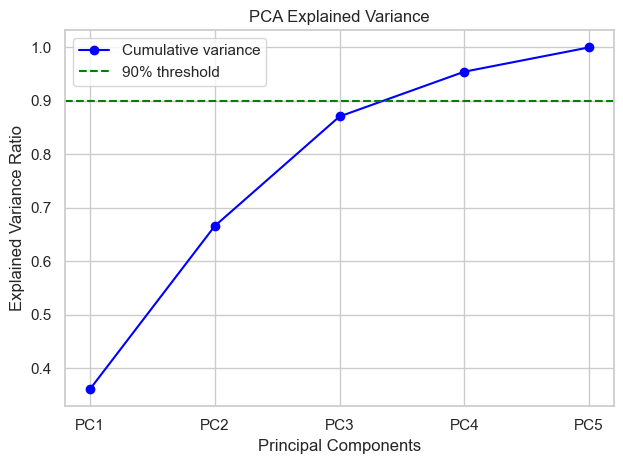

In [27]:
plt.plot(
    pca_variance["Principal_Component"],
    pca_variance["Cumulative_Variance"],
    marker="o",
    color="blue",
    label="Cumulative variance"
)

plt.axhline(
    y=0.90,
    color="green",
    linestyle="--",
    label="90% threshold"
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
pca = PCA(n_components=4)

X_pca = pca.fit_transform(scaled_features)

pca_data = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2", "PC3", "PC4"],
    index=clustering_data.index
)

print("Dataset before PCA:", scaled_features.shape)
print("Dataset after PCA:", pca_data.shape)
print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

Dataset before PCA: (2493, 5)
Dataset after PCA: (2493, 4)
Total explained variance: 0.9546156112604982


PCA reduced the five scaled characteristics to four components, retaining 95.46% of the total variance. The final dataset contained 2,493 observations and four uncorrelated components for clustering.

In [29]:
print(type(X_scaled))
print(type(X_pca))
print(type(pca_data))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'pandas.core.frame.DataFrame'>


## K-Means Clustering

K-Means will be applied to divide the trading observations into groups by minimising the variation within each cluster (MacQueen, 1967). The Elbow Method, Silhouette Score and Davies–Bouldin Index will be used to support the selection of the number of clusters.

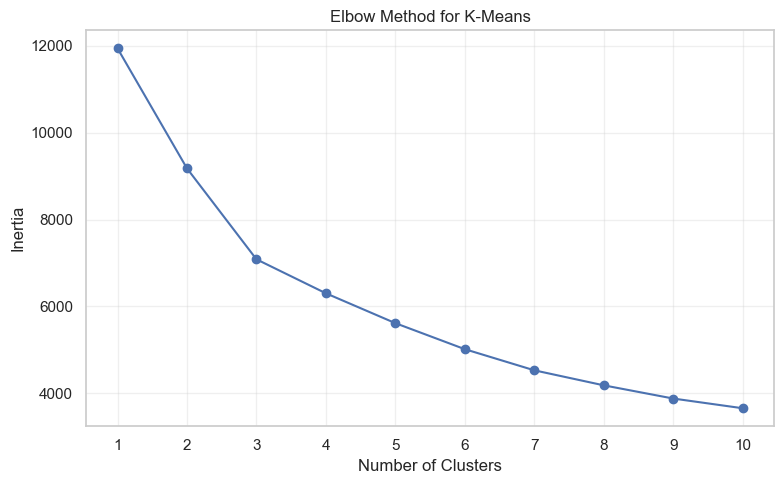

In [30]:

inertia_values = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(pca_data)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The Elbow Method was used to identify a suitable number of clusters by comparing the K-Means inertia for values of k from 1 to 10.

In [31]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

silhouette_results = []

for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(pca_data)

    score = silhouette_score(
        pca_data,
        labels
    )

    silhouette_results.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": score
    })

silhouette_table = pd.DataFrame(silhouette_results)
silhouette_table

,Number_of_Clusters,Silhouette_Score
0,2,0.380817
1,3,0.363085
2,4,0.336586
3,5,0.283077
4,6,0.264553


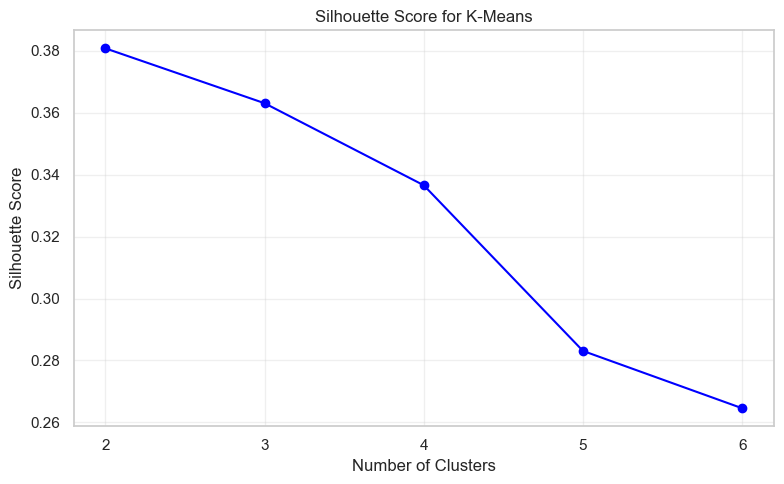

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    silhouette_table["Number_of_Clusters"],
    silhouette_table["Silhouette_Score"],
    marker="o",
    color="blue"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for K-Means")
plt.xticks(range(2, 7))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Analysis of the Elbow Method suggests that three groupings may be appropriate, as the reduction in inertia becomes more gradual after k = 3. The Silhouette Score was subsequently calculated to confirm this selection

In [33]:

evaluation_results = []

for k in range(2, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(pca_data)

    evaluation_results.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": silhouette_score(
            pca_data,
            labels
        ),
        "Davies_Bouldin_Index": davies_bouldin_score(
            pca_data,
            labels
        )
    })

cluster_evaluation = pd.DataFrame(evaluation_results)
cluster_evaluation

,Number_of_Clusters,Silhouette_Score,Davies_Bouldin_Index
0,2,0.380817,1.305408
1,3,0.363085,1.172234
2,4,0.336586,1.142388
3,5,0.283077,1.202352
4,6,0.264553,1.151742


The evaluation metrics did not identify a single best value of k. Two clusters achieved the highest Silhouette Score (0.381), while four clusters achieved the lowest Davies–Bouldin Index (1.142). However, the Elbow Method indicated diminishing improvements after k = 3. Three clusters also produced a meaningful distinction between stable, positive high-activity and negative high-activity trading days. Therefore, k = 3 was selected as a compromise between statistical performance and market interpretability.

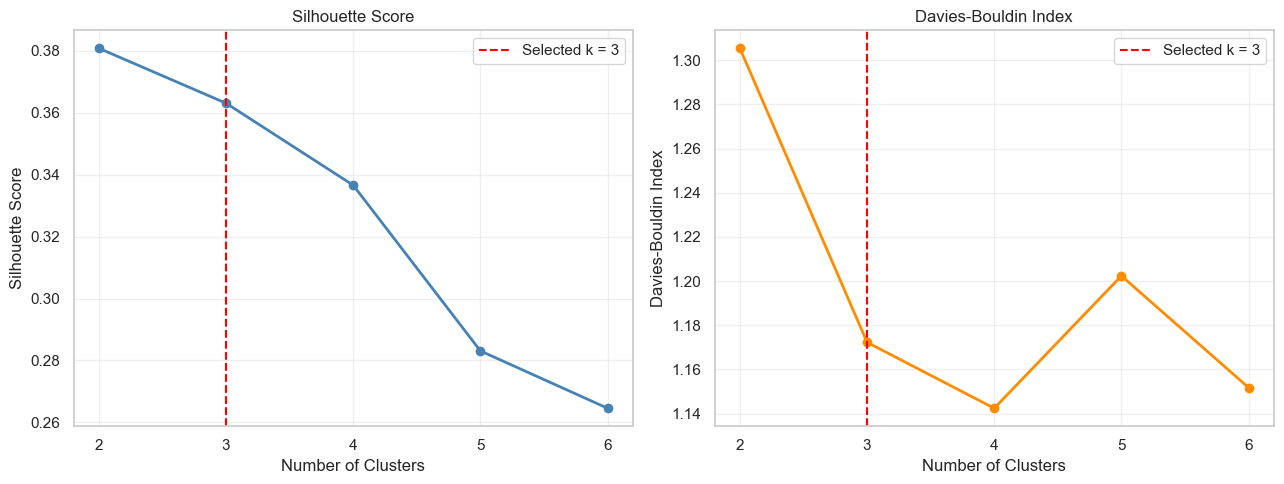

In [34]:
plt.close("all")

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 5)
)

# Silhouette Score
axes[0].plot(
    cluster_evaluation["Number_of_Clusters"],
    cluster_evaluation["Silhouette_Score"],
    marker="o",
    linewidth=2,
    color="steelblue"
)

axes[0].set_title("Silhouette Score")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Silhouette Score")
axes[0].set_xticks(
    cluster_evaluation["Number_of_Clusters"]
)
axes[0].grid(alpha=0.3)

# Davies-Bouldin Index
axes[1].plot(
    cluster_evaluation["Number_of_Clusters"],
    cluster_evaluation["Davies_Bouldin_Index"],
    marker="o",
    linewidth=2,
    color="darkorange"
)

axes[1].set_title("Davies-Bouldin Index")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Davies-Bouldin Index")
axes[1].set_xticks(
    cluster_evaluation["Number_of_Clusters"]
)
axes[1].grid(alpha=0.3)

axes[0].axvline(
    x=3,
    color="red",
    linestyle="--",
    label="Selected k = 3"
)

axes[1].axvline(
    x=3,
    color="red",
    linestyle="--",
    label="Selected k = 3"
)

axes[0].legend()
axes[1].legend()
fig.tight_layout()
plt.show()

In [35]:
kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(pca_data)

clustering_data["KMeans_Cluster"] = kmeans_labels

print("Number of observations in each cluster:")
print(
    clustering_data["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

Number of observations in each cluster:
KMeans_Cluster
0    1680
1     430
2     383
Name: count, dtype: int64


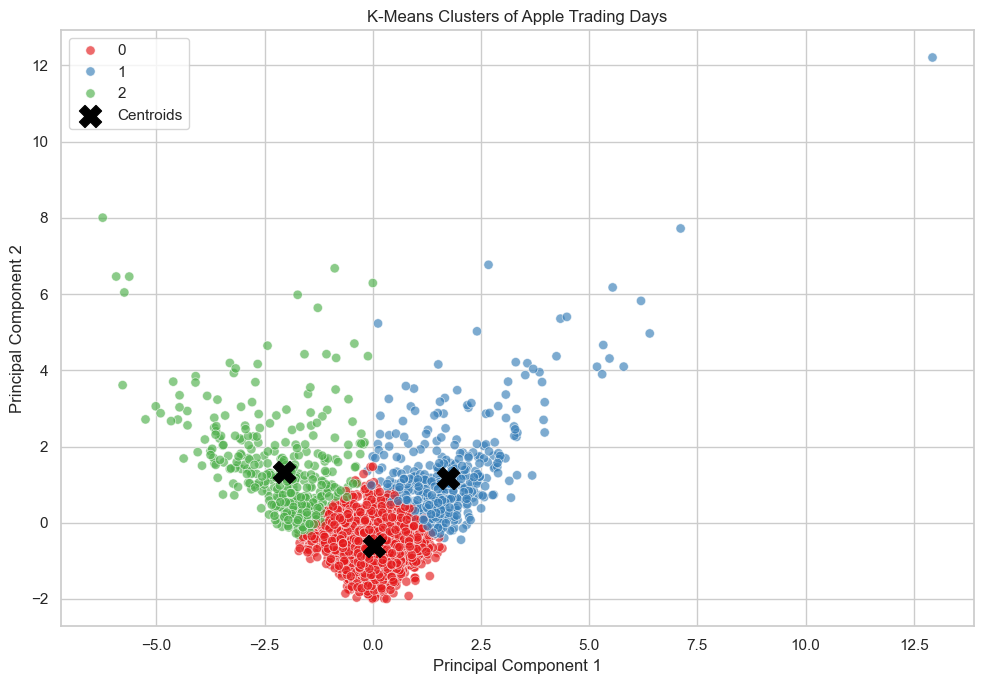

In [36]:
pca_plot = pca_data.copy()
pca_plot["Cluster"] = kmeans_labels

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_plot,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    alpha=0.65,
    s=45
)

plt.scatter(
    kmeans_final.cluster_centers_[:, 0],
    kmeans_final.cluster_centers_[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.title("K-Means Clusters of Apple Trading Days")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()

In [37]:
cluster_profile = (
    clustering_data
    .groupby("KMeans_Cluster")[feature_columns]
    .mean()
    .round(3)
)

cluster_profile

,Daily_Return,Intraday_Range,Open_Close_Change,Volume_Change,Rolling_Volatility
KMeans_Cluster,,,,,
0,0.113,1.499,0.085,-4.726,1.414
1,2.428,3.047,1.939,19.683,2.181
2,-2.429,3.418,-1.842,31.413,2.149


K-Means identified three interpretable market regimes. Cluster 0 represented relatively stable trading days with low returns and volatility. Cluster 1 contained highly active days with strong positive returns, while Cluster 2 represented highly active days with strong negative returns. The negative return cluster also exhibited the largest average intraday volume variation and amplitude

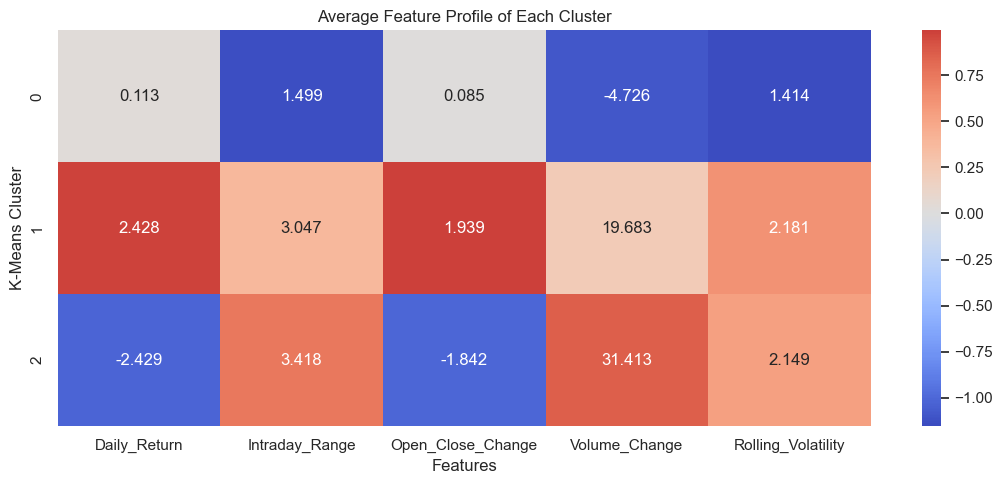

In [38]:
profile_scaled = (
    cluster_profile - cluster_profile.mean()
) / cluster_profile.std()

plt.figure(figsize=(11, 5))

sns.heatmap(
    profile_scaled,
    annot=cluster_profile,
    fmt=".3f",
    cmap="coolwarm",
    center=0
)

plt.title("Average Feature Profile of Each Cluster")
plt.xlabel("Features")
plt.ylabel("K-Means Cluster")
plt.tight_layout()
plt.show()

K-Means identified three distinct market regimes. Cluster 0 represents relatively stable trading days, Cluster 1 represents days with strong positive returns, and Cluster 2 represents days with strong negative returns and higher daily movement

In [39]:
cluster_names = {
    0: "Stable Market",
    1: "Positive High Activity",
    2: "Negative High Activity"
}

clustering_data["Market_Regime"] = (
    clustering_data["KMeans_Cluster"]
    .map(cluster_names)
)

print(clustering_data["Market_Regime"].value_counts())

Market_Regime
Stable Market             1680
Positive High Activity     430
Negative High Activity     383
Name: count, dtype: int64


In [40]:
regime_summary = (
    clustering_data["Market_Regime"]
    .value_counts()
    .to_frame(name="Number_of_Days")
)

regime_summary["Percentage"] = (
    regime_summary["Number_of_Days"]
    / len(clustering_data)
    * 100
).round(2)

regime_summary

,Number_of_Days,Percentage
Market_Regime,,
Stable Market,1680,67.39
Positive High Activity,430,17.25
Negative High Activity,383,15.36


Based on the data, it is possible to classify these as days of stable market conditions, which account for 67.39% of the dataset. Days of high positive activity represented 17.25%, while days of high negative activity accounted for 15.36%. This indicates that pronounced market movements—whether positive or negative—occurred less frequently than stable trading conditions.

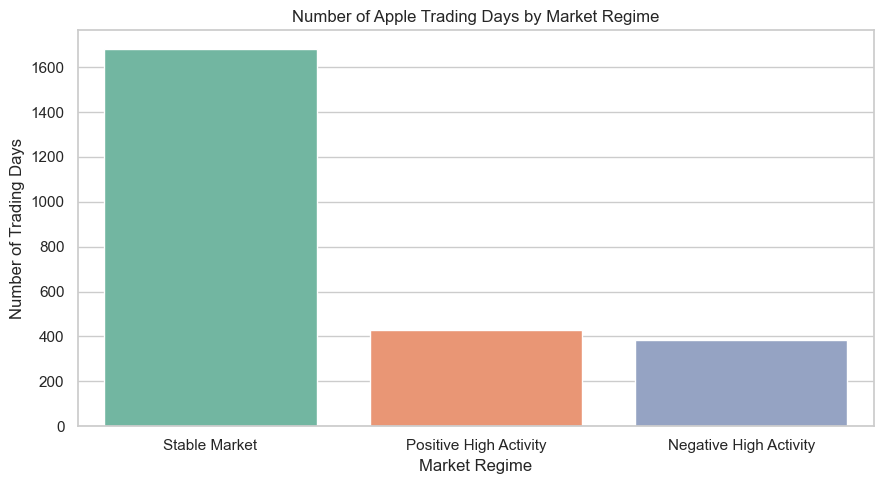

In [41]:
regime_counts = (
    clustering_data["Market_Regime"]
    .value_counts()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=regime_counts.index,
    y=regime_counts.values,
    hue=regime_counts.index,
    palette="Set2",
    legend=False
)

plt.title("Number of Apple Trading Days by Market Regime")
plt.xlabel("Market Regime")
plt.ylabel("Number of Trading Days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

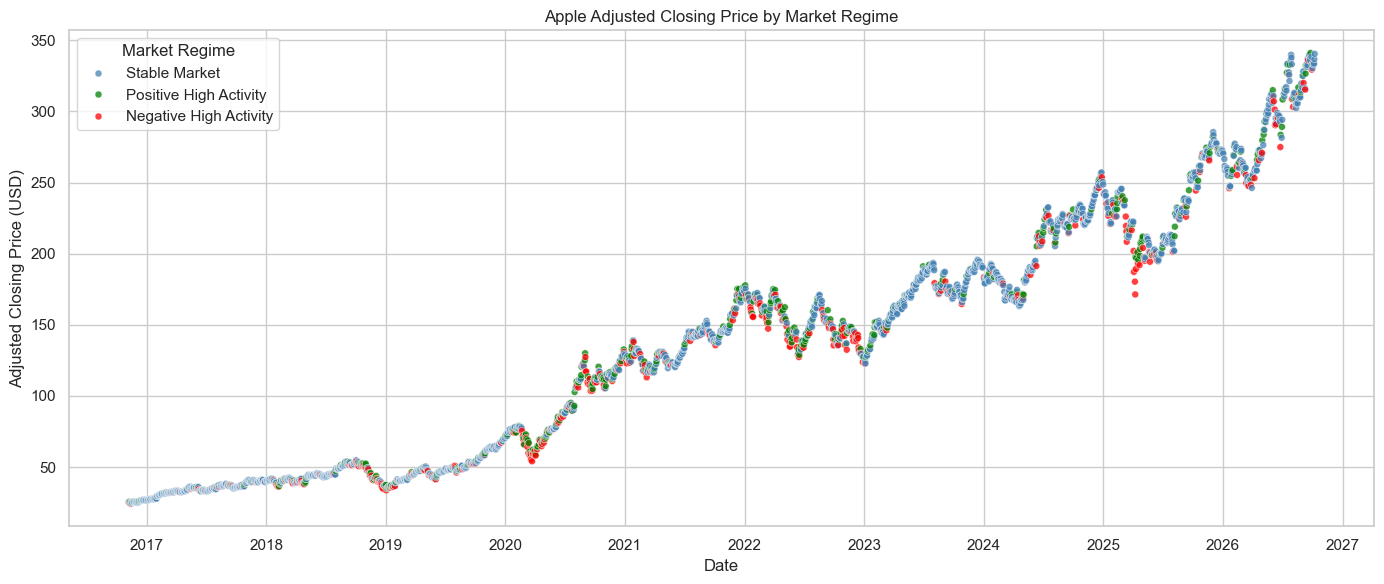

In [42]:
plt.figure(figsize=(14, 6))

sns.scatterplot(
    data=clustering_data,
    x="Date",
    y="Adj Close",
    hue="Market_Regime",
    palette={
        "Stable Market": "steelblue",
        "Positive High Activity": "green",
        "Negative High Activity": "red"
    },
    s=25,
    alpha=0.75
)

plt.title("Apple Adjusted Closing Price by Market Regime")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")
plt.legend(title="Market Regime")
plt.tight_layout()
plt.show()

The graph shows that Stable Market days were the most common throughout the period. Positive High Activity and Negative High Activity days occurred less often and appeared mainly during larger daily price movements. The three regimes were found at different stock price levels.

## DBSCAN Clustering

DBSCAN will be applied as a second unsupervised learning model. Unlike K-Means, DBSCAN identifies clusters based on data density and can classify isolated observations as noise (Ester et al., 1996). The same four principal components used in K-Means will be used to allow a consistent comparison between the models.

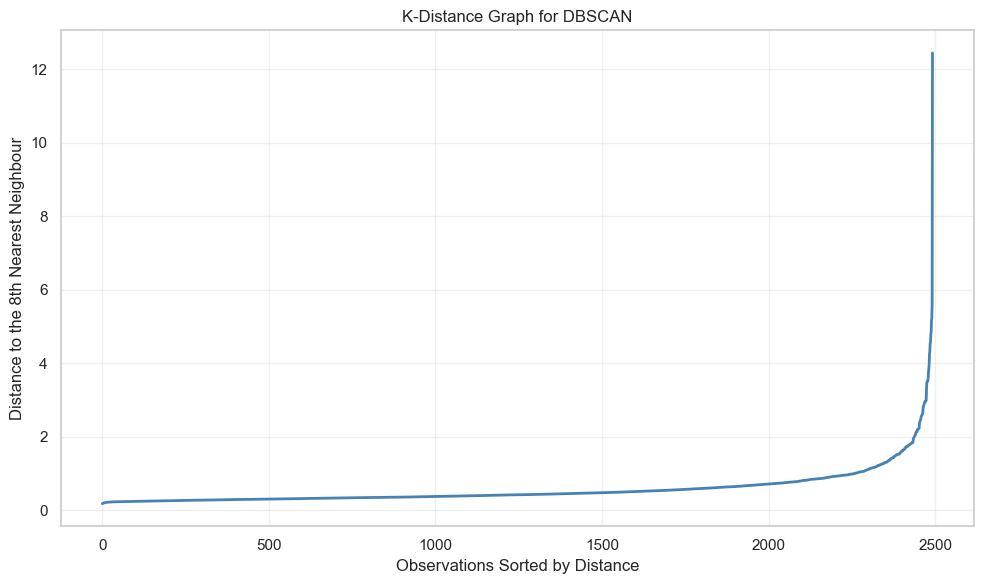

In [43]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

min_samples = 8

nearest_neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

nearest_neighbors.fit(pca_data)

distances, _ = nearest_neighbors.kneighbors()

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 6))

plt.plot(
    k_distances,
    color="steelblue",
    linewidth=2
)

plt.title("K-Distance Graph for DBSCAN")
plt.xlabel("Observations Sorted by Distance")
plt.ylabel("Distance to the 8th Nearest Neighbour")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The k-distance graph was used to identify an appropriate range for the DBSCAN eps parameter. The curve begins to rise more sharply at approximately 1.5 to 2.0, indicating a possible separation between dense observations and isolated points. Therefore, values within this range will be evaluated before selecting the final DBSCAN parameters.

In [44]:
eps_values = [1.4, 1.6, 1.8, 2.0]

In [45]:
eps_values = [1.4, 1.6, 1.8, 2.0]
min_samples_values = [6, 8, 10]

dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        dbscan_test = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan_test.fit_predict(pca_data)

        
        noise_mask = labels == -1
        non_noise_labels = labels[~noise_mask]
        non_noise_data = pca_data.loc[~noise_mask]

        number_of_clusters = len(
            set(labels) - {-1}
        )

        number_of_noise_points = noise_mask.sum()
        noise_percentage = (
            number_of_noise_points / len(labels)
        ) * 100

        
        if (
            number_of_clusters >= 2
            and len(non_noise_data) > number_of_clusters
        ):
            silhouette = silhouette_score(
                non_noise_data,
                non_noise_labels
            )

            davies_bouldin = davies_bouldin_score(
                non_noise_data,
                non_noise_labels
            )
        else:
            silhouette = np.nan
            davies_bouldin = np.nan

        dbscan_results.append({
            "Eps": eps,
            "Min_Samples": min_samples,
            "Number_of_Clusters": number_of_clusters,
            "Noise_Points": number_of_noise_points,
            "Noise_Percentage": noise_percentage,
            "Silhouette_Score": silhouette,
            "Davies_Bouldin_Index": davies_bouldin
        })

dbscan_evaluation = pd.DataFrame(dbscan_results)

dbscan_evaluation.round(4)

,Eps,Min_Samples,Number_of_Clusters,Noise_Points,Noise_Percentage,Silhouette_Score,Davies_Bouldin_Index
0,1.4,6,1,61,2.4469,NaN,NaN
1,1.4,8,1,66,2.6474,NaN,NaN
2,1.4,10,1,74,2.9683,NaN,NaN
3,1.6,6,1,42,1.6847,NaN,NaN
4,1.6,8,1,48,1.9254,NaN,NaN
5,1.6,10,1,50,2.0056,NaN,NaN
6,1.8,6,2,27,1.0830,0.6309,0.4862
7,1.8,8,1,39,1.5644,NaN,NaN
8,1.8,10,1,42,1.6847,NaN,NaN
9,2.0,6,1,22,0.8825,NaN,NaN


In [46]:
dbscan_candidate = DBSCAN(
    eps=1.8,
    min_samples=6
)

dbscan_candidate_labels = dbscan_candidate.fit_predict(pca_data)

# Count observations in each cluster and noise
dbscan_cluster_counts = (
    pd.Series(dbscan_candidate_labels, name="DBSCAN_Cluster")
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Number_of_Observations")
)

dbscan_cluster_counts["Percentage"] = (
    dbscan_cluster_counts["Number_of_Observations"]
    / len(pca_data)
    * 100
)

dbscan_cluster_counts.round(2)


,Cluster,Number_of_Observations,Percentage
0,-1,27,1.08
1,0,2458,98.60
2,1,8,0.32


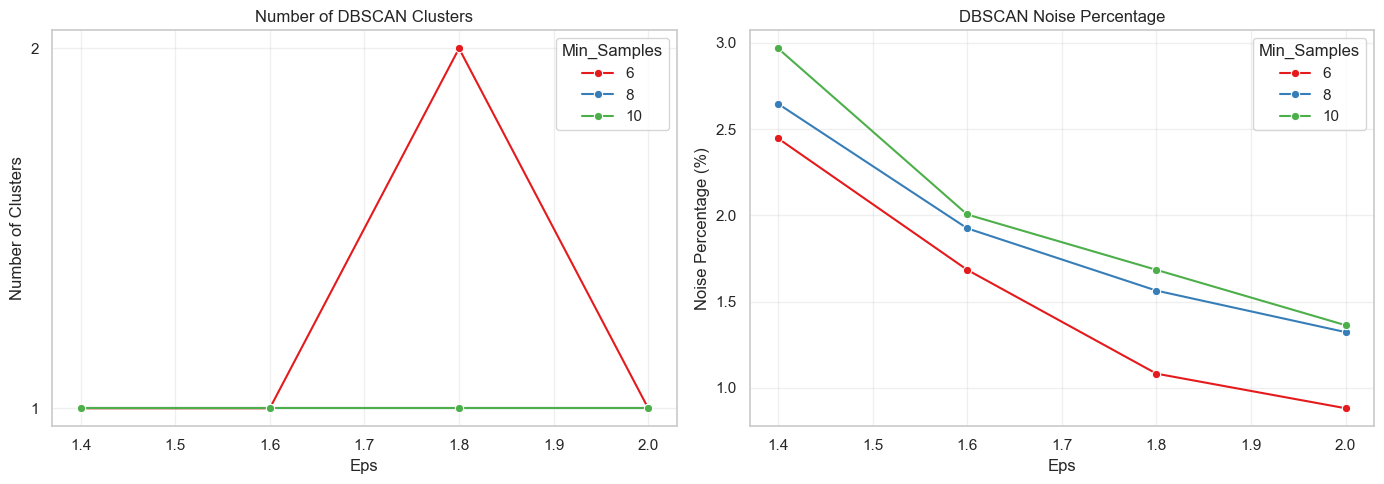

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


sns.lineplot(
    data=dbscan_evaluation,
    x="Eps",
    y="Number_of_Clusters",
    hue="Min_Samples",
    marker="o",
    palette="Set1",
    ax=axes[0]
)

axes[0].set_title("Number of DBSCAN Clusters")
axes[0].set_xlabel("Eps")
axes[0].set_ylabel("Number of Clusters")
axes[0].set_yticks(
    sorted(dbscan_evaluation["Number_of_Clusters"].unique())
)
axes[0].grid(alpha=0.3)


sns.lineplot(
    data=dbscan_evaluation,
    x="Eps",
    y="Noise_Percentage",
    hue="Min_Samples",
    marker="o",
    palette="Set1",
    ax=axes[1]
)

axes[1].set_title("DBSCAN Noise Percentage")
axes[1].set_xlabel("Eps")
axes[1].set_ylabel("Noise Percentage (%)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Parameter comparison shows that most DBSCAN configurations identified one main cluster. Only eps=1.8 and min_samples=6 produced two clusters. The noise percentage decreased with increasing eps, as more observations were connected to dense regions. The solution with two clusters requires further analysis, as it appeared in only one parameter combination

DBSCAN Cluster Visualisation

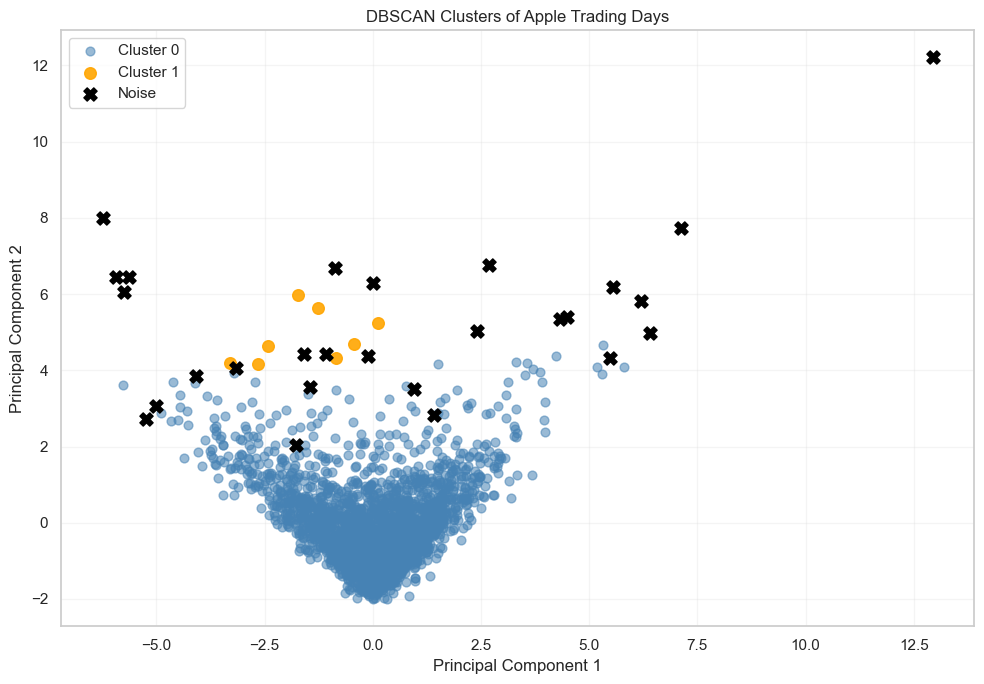

In [48]:
dbscan_plot = pca_data.copy()
dbscan_plot["DBSCAN_Cluster"] = dbscan_candidate_labels

plt.figure(figsize=(10, 7))

# Main cluster
main_cluster = dbscan_plot[
    dbscan_plot["DBSCAN_Cluster"] == 0
]

plt.scatter(
    main_cluster["PC1"],
    main_cluster["PC2"],
    color="steelblue",
    alpha=0.55,
    s=40,
    label="Cluster 0"
)

# Small cluster
small_cluster = dbscan_plot[
    dbscan_plot["DBSCAN_Cluster"] == 1
]

plt.scatter(
    small_cluster["PC1"],
    small_cluster["PC2"],
    color="orange",
    alpha=0.9,
    s=70,
    label="Cluster 1"
)

# Noise
noise_points = dbscan_plot[
    dbscan_plot["DBSCAN_Cluster"] == -1
]

plt.scatter(
    noise_points["PC1"],
    noise_points["PC2"],
    color="black",
    marker="X",
    s=90,
    label="Noise"
)

plt.title("DBSCAN Clusters of Apple Trading Days")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


DBSCAN Cluster Profile

In [49]:


dbscan_profile_data = clustering_data.copy()

print("Dataset rows:", len(dbscan_profile_data))
print("DBSCAN labels:", len(dbscan_candidate_labels))

Dataset rows: 2493
DBSCAN labels: 2493


In [50]:
dbscan_profile_data["DBSCAN_Cluster"] = (
    dbscan_candidate_labels
)

# Give understandable names to the groups
dbscan_group_names = {
    -1: "Noise",
     0: "Main Dense Cluster",
     1: "Small Cluster"
}

dbscan_profile_data["DBSCAN_Group"] = (
    dbscan_profile_data["DBSCAN_Cluster"]
    .map(dbscan_group_names)
)

# Features used in the clustering analysis
dbscan_feature_columns = [
    "Daily_Return",
    "Intraday_Range",
    "Open_Close_Change",
    "Volume_Change",
    "Rolling_Volatility"
]

# Calculate the average of each feature by group
dbscan_profile = (
    dbscan_profile_data
    .groupby("DBSCAN_Group")[dbscan_feature_columns]
    .mean()
    .round(3)
)

dbscan_profile

,Daily_Return,Intraday_Range,Open_Close_Change,Volume_Change,Rolling_Volatility
DBSCAN_Group,,,,,
Main Dense Cluster,0.125,1.998,0.100,4.287,1.619
Noise,0.510,7.036,1.331,76.147,3.851
Small Cluster,-2.082,4.776,-1.356,-4.889,6.447


DBSCAN Group Profile Heatmap

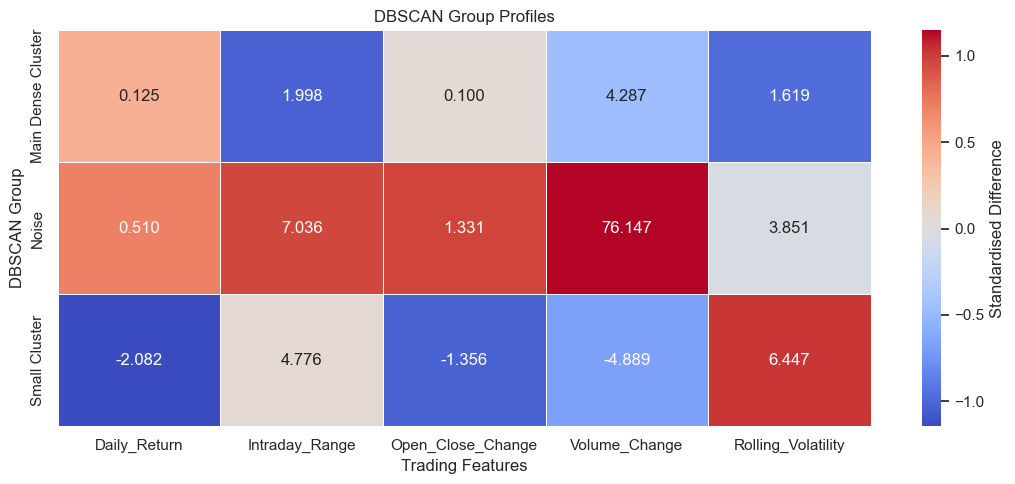

In [51]:
# Standardise the group averages for heatmap colours
dbscan_profile_scaled = (
    dbscan_profile - dbscan_profile.mean()
) / dbscan_profile.std()

plt.figure(figsize=(11, 5))

sns.heatmap(
    dbscan_profile_scaled,
    annot=dbscan_profile,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Standardised Difference"}
)

plt.title("DBSCAN Group Profiles")
plt.xlabel("Trading Features")
plt.ylabel("DBSCAN Group")
plt.tight_layout()
plt.show()

The heatmap shows that the main dense cluster exhibited relatively moderate trading behavior. The noise observations showed the greatest intraday amplitude and volume variation, indicating atypical trading activity. The small cluster showed a negative average return and the highest accumulated volatility. However, this group contained only eight observations, so it should be interpreted with caution. Overall, DBSCAN was more useful for identifying atypical trading days than for producing balanced market regimes.

## Model Comparison: K-Means and DBSCAN

In [52]:
# K-Means metrics
kmeans_silhouette = silhouette_score(
    pca_data,
    kmeans_labels
)

kmeans_davies_bouldin = davies_bouldin_score(
    pca_data,
    kmeans_labels
)

kmeans_number_of_clusters = len(
    set(kmeans_labels)
)

kmeans_largest_group = (
    pd.Series(kmeans_labels)
    .value_counts(normalize=True)
    .max()
    * 100
)

# DBSCAN metrics excluding noise
dbscan_non_noise_mask = (
    dbscan_candidate_labels != -1
)

dbscan_non_noise_data = pca_data.loc[
    dbscan_non_noise_mask
]

dbscan_non_noise_labels = (
    dbscan_candidate_labels[dbscan_non_noise_mask]
)

dbscan_silhouette = silhouette_score(
    dbscan_non_noise_data,
    dbscan_non_noise_labels
)

dbscan_davies_bouldin = davies_bouldin_score(
    dbscan_non_noise_data,
    dbscan_non_noise_labels
)

dbscan_number_of_clusters = len(
    set(dbscan_candidate_labels) - {-1}
)

dbscan_noise_percentage = (
    (dbscan_candidate_labels == -1).mean()
    * 100
)

dbscan_largest_group = (
    pd.Series(dbscan_candidate_labels)
    .value_counts(normalize=True)
    .max()
    * 100
)

# Create the comparison table
model_comparison = pd.DataFrame({
    "Model": ["K-Means", "DBSCAN"],
    "Number_of_Clusters": [
        kmeans_number_of_clusters,
        dbscan_number_of_clusters
    ],
    "Silhouette_Score": [
        kmeans_silhouette,
        dbscan_silhouette
    ],
    "Davies_Bouldin_Index": [
        kmeans_davies_bouldin,
        dbscan_davies_bouldin
    ],
    "Noise_Percentage": [
        0,
        dbscan_noise_percentage
    ],
    "Largest_Group_Percentage": [
        kmeans_largest_group,
        dbscan_largest_group
    ]
})

model_comparison.round(4)

,Model,Number_of_Clusters,Silhouette_Score,Davies_Bouldin_Index,Noise_Percentage,Largest_Group_Percentage
0,K-Means,3,0.3631,1.1722,0.000,67.3887
1,DBSCAN,2,0.6309,0.4862,1.083,98.5961


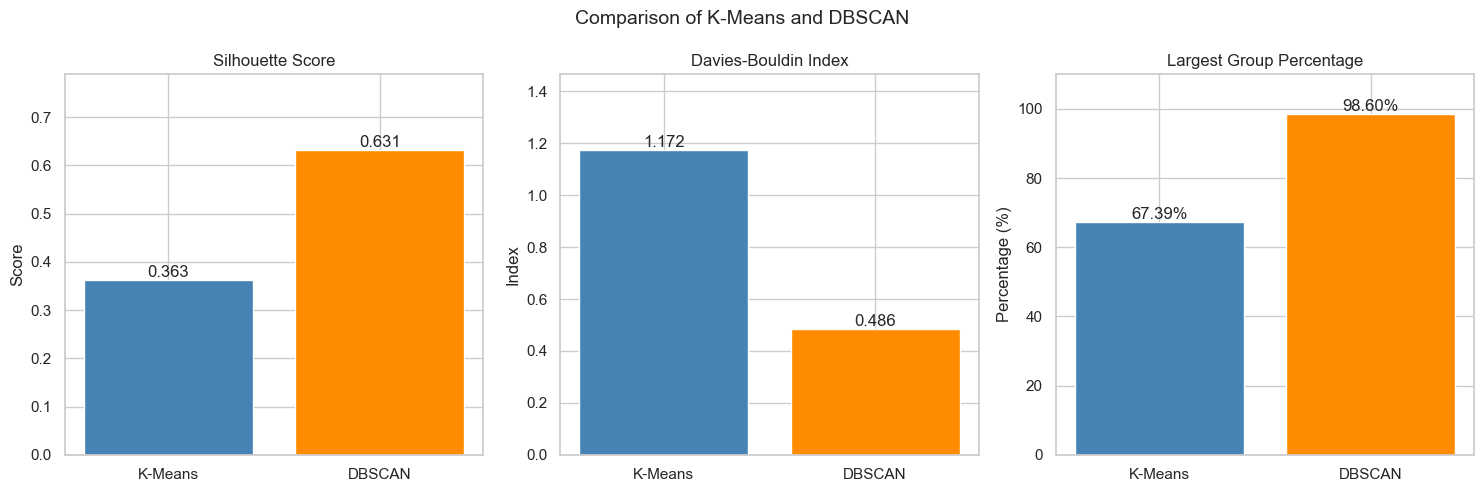

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

models = model_comparison["Model"]
colors = ["steelblue", "darkorange"]

# Silhouette Score
bars_1 = axes[0].bar(
    models,
    model_comparison["Silhouette_Score"],
    color=colors
)

axes[0].bar_label(
    bars_1,
    fmt="%.3f"
)

axes[0].set_title("Silhouette Score")
axes[0].set_ylabel("Score")
axes[0].set_ylim(
    0,
    model_comparison["Silhouette_Score"].max() * 1.25
)

# Davies-Bouldin Index
bars_2 = axes[1].bar(
    models,
    model_comparison["Davies_Bouldin_Index"],
    color=colors
)

axes[1].bar_label(
    bars_2,
    fmt="%.3f"
)

axes[1].set_title("Davies-Bouldin Index")
axes[1].set_ylabel("Index")
axes[1].set_ylim(
    0,
    model_comparison["Davies_Bouldin_Index"].max() * 1.25
)

# Largest group percentage
bars_3 = axes[2].bar(
    models,
    model_comparison["Largest_Group_Percentage"],
    color=colors
)

axes[2].bar_label(
    bars_3,
    fmt="%.2f%%"
)

axes[2].set_title("Largest Group Percentage")
axes[2].set_ylabel("Percentage (%)")
axes[2].set_ylim(0, 110)

plt.suptitle(
    "Comparison of K-Means and DBSCAN",
    fontsize=14
)

plt.tight_layout()
plt.show()

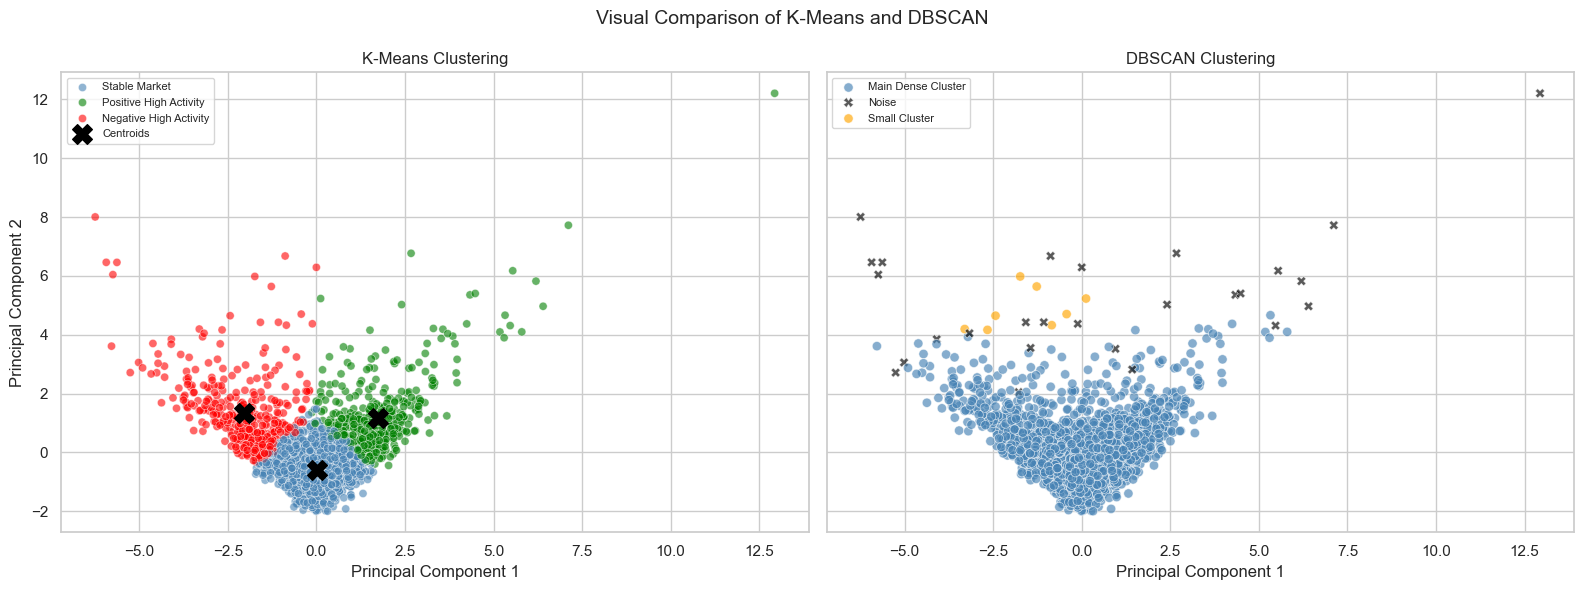

In [54]:
#  K-Means groups
kmeans_comparison_plot = pca_data.copy()

kmeans_comparison_plot["Group"] = (
    pd.Series(
        kmeans_labels,
        index=pca_data.index
    )
    .map(cluster_names)
)

#  DBSCAN groups
dbscan_comparison_plot = pca_data.copy()

dbscan_comparison_plot["Group"] = (
    pd.Series(
        dbscan_candidate_labels,
        index=pca_data.index
    )
    .map(dbscan_group_names)
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6),
    sharex=True,
    sharey=True
)

# K-Means
sns.scatterplot(
    data=kmeans_comparison_plot,
    x="PC1",
    y="PC2",
    hue="Group",
    palette={
        "Stable Market": "steelblue",
        "Positive High Activity": "green",
        "Negative High Activity": "red"
    },
    alpha=0.60,
    s=35,
    ax=axes[0]
)

axes[0].scatter(
    kmeans_final.cluster_centers_[:, 0],
    kmeans_final.cluster_centers_[:, 1],
    marker="X",
    s=200,
    color="black",
    label="Centroids"
)

axes[0].set_title("K-Means Clustering")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].legend(fontsize=8)

# DBSCAN
sns.scatterplot(
    data=dbscan_comparison_plot,
    x="PC1",
    y="PC2",
    hue="Group",
    style="Group",
    palette={
        "Main Dense Cluster": "steelblue",
        "Small Cluster": "orange",
        "Noise": "black"
    },
    markers={
        "Main Dense Cluster": "o",
        "Small Cluster": "o",
        "Noise": "X"
    },
    alpha=0.65,
    s=45,
    ax=axes[1]
)

axes[1].set_title("DBSCAN Clustering")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].legend(fontsize=8)

plt.suptitle(
    "Visual Comparison of K-Means and DBSCAN",
    fontsize=14
)

plt.tight_layout()
plt.show()

Comparison between K-Means and DBSCAN
DBSCAN obtained a higher Silhouette Score (0.631) and a lower Davies–Bouldin Index (0.486) than K-Means (0.363 and 1.172, respectively). However, DBSCAN assigned 98.60% of the observations to a single dominant cluster, while its second cluster contained only eight observations. In addition, its evaluation metrics were calculated after excluding the 27 observations classified as noise.
In contrast, K-Means generated three more balanced and interpretable groups representing the Stable Market, Positive High Activity and Negative High Activity regimes. Therefore, K-Means was selected as the primary model for identifying market regimes, while DBSCAN was retained as a complementary method for identifying atypical trading days.

Time Series Analysis and Forecasting

The adjusted closing price was selected for the time series analysis because it takes into account corporate events such as dividends and stock splits. Observations were organized chronologically, and duplicate dates and missing values were checked before modeling.

In [55]:

time_series_data = data_original[["Date", "Adj Close"]].copy()


time_series_data["Date"] = pd.to_datetime(time_series_data["Date"])


time_series_data = (
    time_series_data
    .sort_values("Date")
    .drop_duplicates(subset="Date")
    .set_index("Date")
)


print(time_series_data.head())
print()
print(time_series_data.tail())
print()
print("Number of observations:", len(time_series_data))
print("Missing values:", time_series_data.isnull().sum().sum())
print(
    "Period analysed:",
    time_series_data.index.min(),
    "until",
    time_series_data.index.max()
)

            Adj Close
Date                 
2016-10-10  26.538967
2016-10-11  26.596134
2016-10-12  26.833969
2016-10-13  26.751650
2016-10-14  26.900293

             Adj Close
Date                  
2026-10-02  333.690002
2026-10-05  332.890015
2026-10-06  333.630005
2026-10-07  336.670013
2026-10-08  340.420013

Number of observations: 2513
Missing values: 0
Period analysed: 2016-10-10 00:00:00 until 2026-10-08 00:00:00


The time series contains 2,513 observations, covering the period from October 2016 to October 2026. No missing values were found in the adjusted closing price, therefore it was not necessary to delete or fill in observations at this stage.

Trend Analysis
The adjusted closing price will be compared to a 60-day moving average. The moving average will be used to smooth out daily fluctuations and facilitate the identification of the overall trend of the series

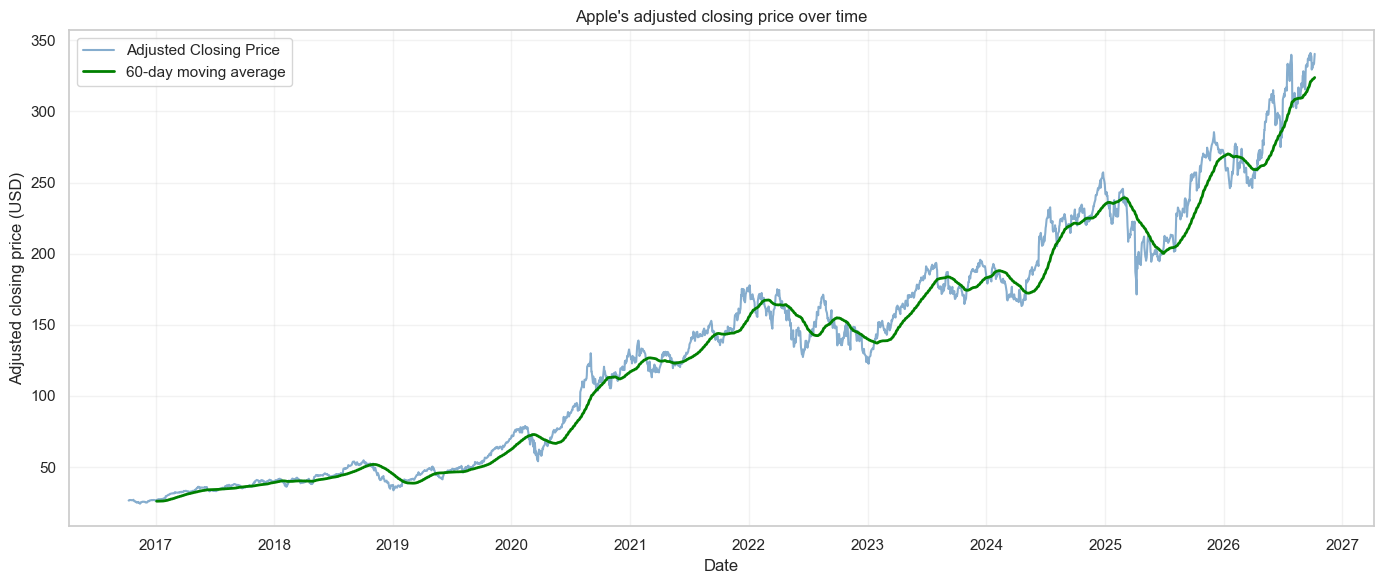

In [56]:
rolling_mean_60 = (
    time_series_data["Adj Close"]
    .rolling(window=60)
    .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    time_series_data.index,
    time_series_data["Adj Close"],
    label="Adjusted Closing Price",
    color="steelblue",
    alpha=0.65
)

plt.plot(
    rolling_mean_60.index,
    rolling_mean_60,
    label="60-day moving average",
    color="green",
    linewidth=2
)

plt.title("Apple's adjusted closing price over time")
plt.xlabel("Date")
plt.ylabel("Adjusted closing price (USD)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

The graphic shows an overall upward trend in the adjusted closing price of Apple stock during the analyzed period. However, dips and recoveries are also observed at different times. The 60-day moving average smooths out daily variations and makes the long-term trend more visible. It is not possible to confirm a regular seasonal pattern based solely on this graphic.

### Stationarity Test

The Augmented Dickey–Fuller test will be applied to determine whether the statistical properties of the series remain stable over time and to support the selection of the ARIMA differencing parameter d (Dickey and Fuller, 1979).

In [57]:
from statsmodels.tsa.stattools import adfuller


adf_result = adfuller(
    time_series_data["Adj Close"].dropna()
)

print("Estatística ADF:", adf_result[0])
print("p-value:", adf_result[1])
print("Número de defasagens utilizadas:", adf_result[2])
print("Número de observações:", adf_result[3])

print("\nValores críticos:")
for level, value in adf_result[4].items():
    print(f"{level}: {value}")

Estatística ADF: 0.6943034962112782
p-value: 0.989723497836854
Número de defasagens utilizadas: 9
Número de observações: 2503

Valores críticos:
1%: -3.4329652692893364
5%: -2.8626954126892405
10%: -2.567385070816339


Since the Augmented Dickey-Fuller test resulted in a p-value of approximately 0.9897 (greater than 0.05), the null hypothesis of a unit root could not be rejected. This shows that the original series of adjusted closing prices is non-stationary. Consequently, the first differencing is adopted to seek stabilization of the series.

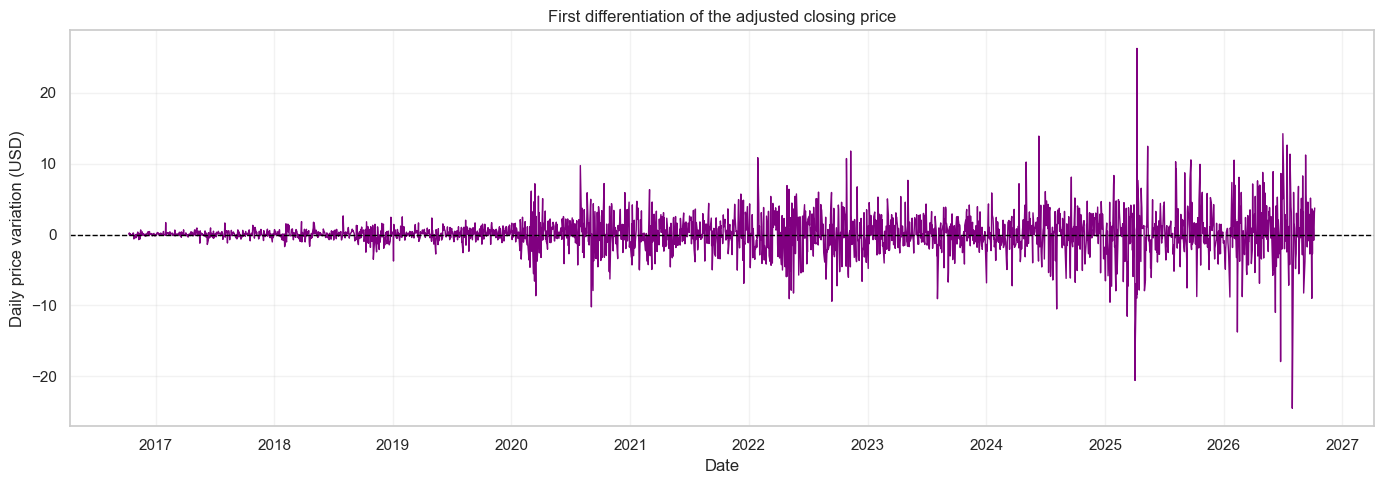

ADF Statistics: -17.159319654478605
p-value: 6.85870725054922e-30
Number of time lags used: 8
Number of observations: 2503

Critical values:
1%: -3.4329652692893364
5%: -2.8626954126892405
10%: -2.567385070816339


In [58]:
first_difference = (
    time_series_data["Adj Close"]
    .diff()
    .dropna()
)

plt.figure(figsize=(14, 5))

plt.plot(
    first_difference.index,
    first_difference,
    color="purple",
    linewidth=1
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("First differentiation of the adjusted closing price")
plt.xlabel("Date")
plt.ylabel("Daily price variation (USD)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


adf_difference_result = adfuller(first_difference)

print("ADF Statistics:", adf_difference_result[0])
print("p-value:", adf_difference_result[1])
print("Number of time lags used:", adf_difference_result[2])
print("Number of observations:", adf_difference_result[3])

print("\nCritical values:")
for level, value in adf_difference_result[4].items():
    print(f"{level}: {value}")

After first differencing, the Augmented Dickey-Fuller test showed a statistic of approximately -17.1593 and a p-value close to zero. Since the p-value is less than 0.05, the null hypothesis was rejected, indicating that the differenced series is stationary. Therefore, one differentiation was sufficient and the parameter d of the ARIMA model was set to 1.

Identification of parameters p and q
The ACF and PACF charts will be used to analyze the autocorrelation of the series after first differencing. The ACF will assist in selecting the moving average parameter q, while the PACF will assist in selecting the autoregressive parameter p.

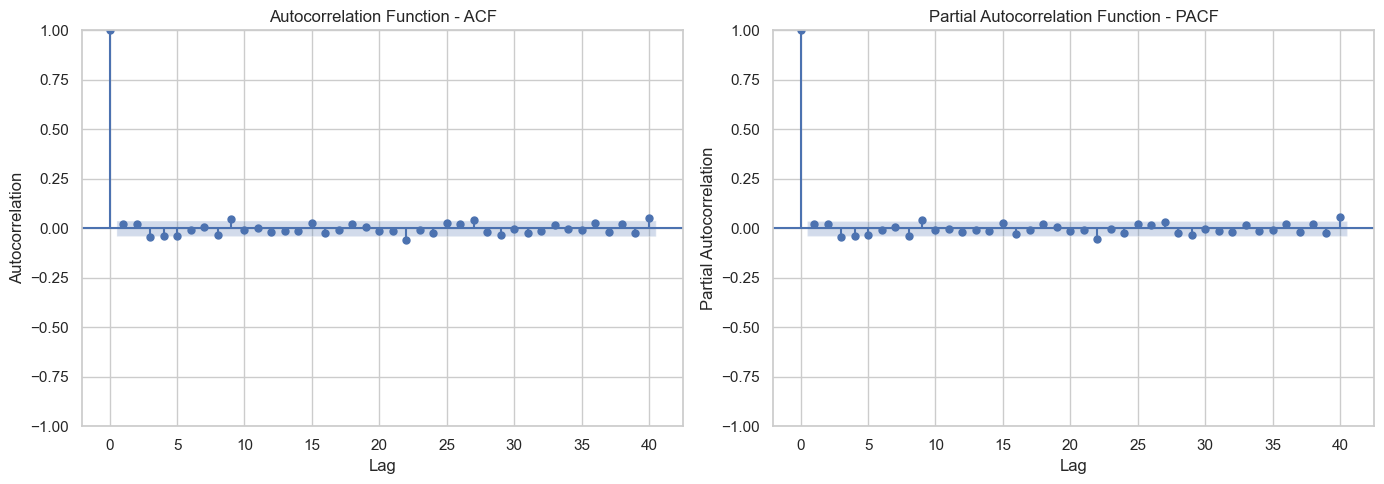

In [59]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    first_difference,
    lags=40,
    ax=axes[0],
    alpha=0.05
)

axes[0].set_title("Autocorrelation Function - ACF")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Autocorrelation")

plot_pacf(
    first_difference,
    lags=40,
    ax=axes[1],
    alpha=0.05,
    method="ywm"
)

axes[1].set_title("Partial Autocorrelation Function - PACF")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Partial Autocorrelation")

plt.tight_layout()
plt.show()

Time series decomposition

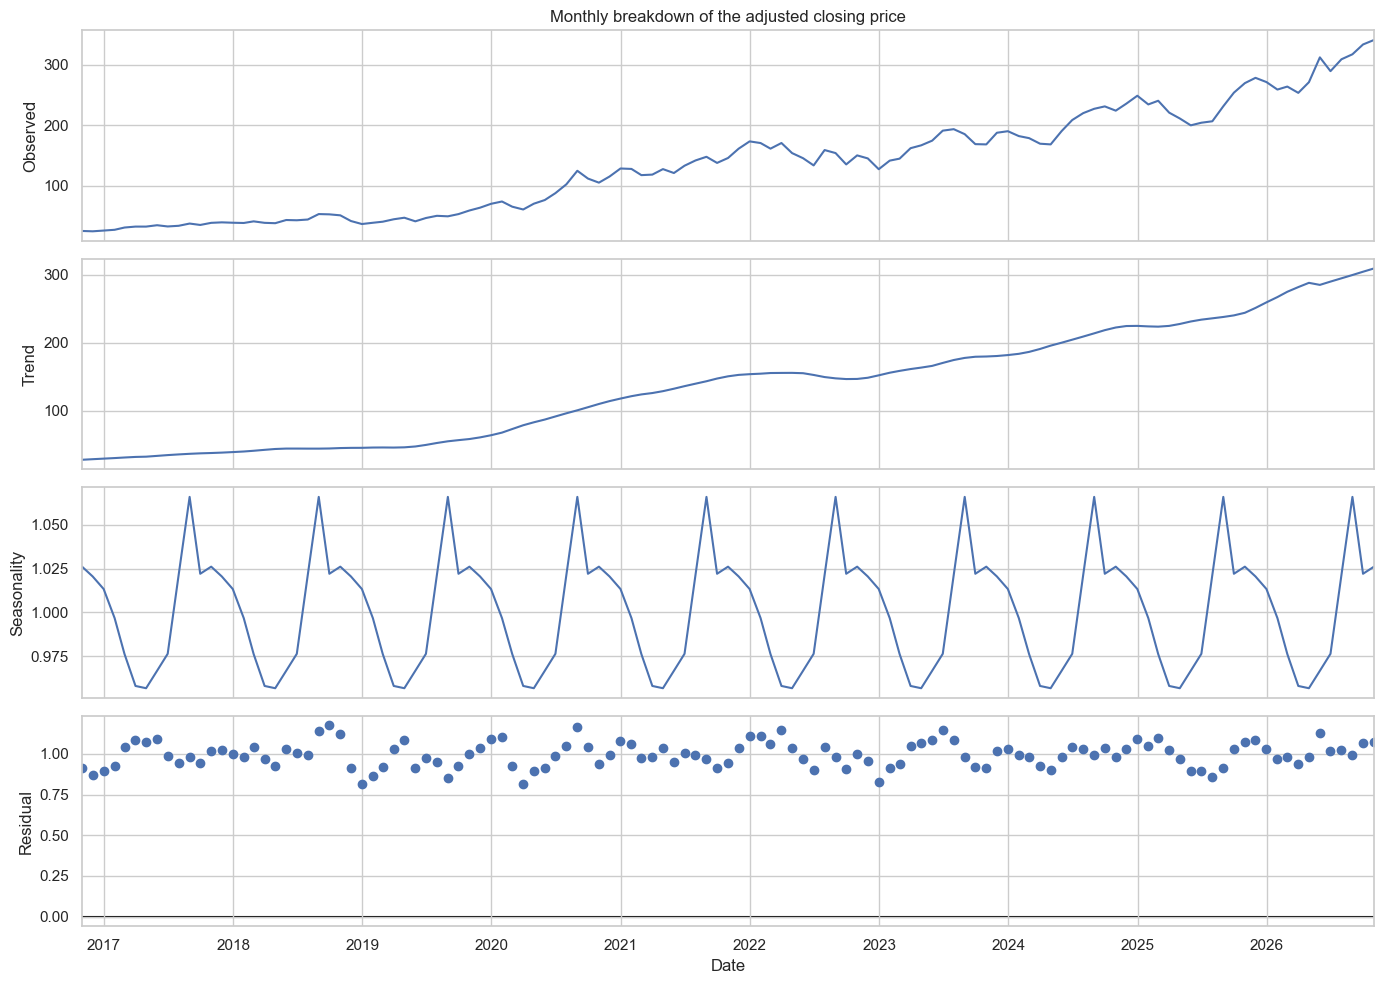

In [60]:
from statsmodels.tsa.seasonal import seasonal_decompose

monthly_prices = (
    time_series_data["Adj Close"]
    .resample("ME")
    .last()
    .dropna()
)

decomposition = seasonal_decompose(
    monthly_prices,
    model="multiplicative",
    period=12,
    extrapolate_trend="freq"
)

fig = decomposition.plot()
fig.set_size_inches(14, 10)

fig.axes[0].set_title(
    "Monthly breakdown of the adjusted closing price"
)
fig.axes[0].set_ylabel("Observed")
fig.axes[1].set_ylabel("Trend")
fig.axes[2].set_ylabel("Seasonality")
fig.axes[3].set_ylabel("Residual")
fig.axes[3].set_xlabel("Date")

plt.tight_layout()
plt.show()

Monthly analysis corroborates a predominantly upward trend in Apple's adjusted value, despite periods of retraction and recovery. The seasonal factor exhibits a cyclical annual behavior; however, its proportional oscillation is subtle when compared to long-term evolution. The residuals reveal fluctuations that were not justified by trend and seasonality variables. Considering also the lack of clear seasonal protrusions in the ACF and PACF diagrams of the daily sequence, the non-seasonal ARIMA model will be adopted in the initial stage.

Chronological division between training and testing

In [61]:
price_series = time_series_data["Adj Close"].copy()


test_size = int(len(price_series) * 0.10)


train_series = price_series.iloc[:-test_size]
test_series = price_series.iloc[-test_size:]

print("Training observations:", len(train_series))
print("Test observations:", len(test_series))

print(
    "Training period:",
    train_series.index.min(),
    "until",
    train_series.index.max()
)

print(
    "Test period:",
    test_series.index.min(),
    "until",
    test_series.index.max()
)

Training observations: 2262
Test observations: 251
Training period: 2016-10-10 00:00:00 until 2025-10-08 00:00:00
Test period: 2025-10-09 00:00:00 until 2026-10-08 00:00:00


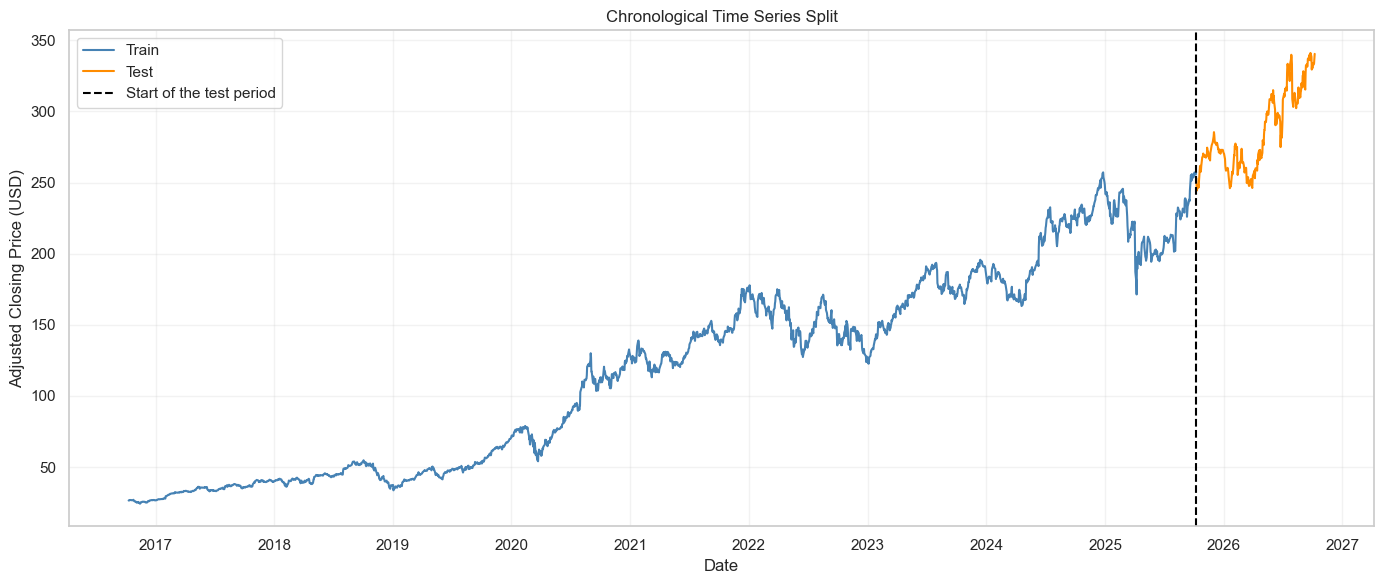

In [62]:
plt.figure(figsize=(14, 6))

plt.plot(
    train_series.index,
    train_series,
    label="Train",
    color="steelblue"
)

plt.plot(
    test_series.index,
    test_series,
    label="Test",
    color="darkorange"
)

plt.axvline(
    test_series.index[0],
    color="black",
    linestyle="--",
    label="Start of the test period"
)

plt.title("Chronological Time Series Split")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

The series was divided into 2,262 training observations and 251 test observations. The training period ends on October 8, 2025, while the test period begins on October 9, 2025, and roughly represents the last year of trading. The chronological order was preserved to avoid using future information during model training.

__Selection of ARIMA model parameters__

Since the ACF and PACF plots did not present a clear cutoff point, combinations of low values for p and q will be evaluated, keeping d = 1. The models will be compared using the AIC and BIC criteria, where lower values indicate a better balance between fit and complexity.

In [63]:
from statsmodels.tsa.arima.model import ARIMA


arima_results = []


train_values = train_series.to_numpy()

# Test values of p and q between 0 and 3
for p in range(4):
    for q in range(4):
        try:
            model = ARIMA(
                train_values,
                order=(p, 1, q)
            )

            fitted_model = model.fit()

            arima_results.append({
                "p": p,
                "d": 1,
                "q": q,
                "AIC": fitted_model.aic,
                "BIC": fitted_model.bic
            })

        except Exception as error:
            print(
                f"ARIMA({p},1,{q}) could not be fitted:",
                error
            )


arima_comparison = pd.DataFrame(arima_results)


arima_comparison = (
    arima_comparison
    .sort_values("AIC")
    .reset_index(drop=True)
)

arima_comparison.round(3)

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


,p,d,q,AIC,BIC
0,1,1,3,10419.020,10447.638
1,3,1,1,10419.091,10447.708
2,3,1,0,10420.477,10443.371
3,0,1,3,10420.679,10443.573
4,2,1,2,10420.679,10449.297
5,2,1,3,10421.015,10455.356
6,3,1,2,10421.072,10455.414
7,0,1,0,10421.160,10426.883
8,0,1,2,10422.681,10439.852
9,1,1,0,10422.745,10434.192


Different combinations of p and q were compared while keeping d = 1. ARIMA(1,1,3) achieved the lowest AIC (10419.023), whereas ARIMA(0,1,0) achieved the lowest BIC (10426.886). As AIC and BIC favoured different levels of complexity, ARIMA(1,1,3) was retained as the main statistical model based on AIC, while the simpler Naive Forecast was later included as a baseline. Out-of-sample evaluation was used to determine whether the additional complexity improved forecasting performance

In [64]:
from statsmodels.tsa.arima.model import ARIMA

final_arima = ARIMA(
    train_series.to_numpy(),
    order=(1, 1, 3)
)

final_arima_fit = final_arima.fit()

print(final_arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2262
Model:                 ARIMA(1, 1, 3)   Log Likelihood               -5204.510
Date:                Fri, 30 Oct 2026   AIC                          10419.020
Time:                        01:31:38   BIC                          10447.638
Sample:                             0   HQIC                         10429.463
                               - 2262                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6595      0.146      4.531      0.000       0.374       0.945
ma.L1         -0.6475      0.148     -4.381      0.000      -0.937      -0.358
ma.L2          0.0204      0.016      1.313      0.1

The ARIMA(1,1,3) model was fitted using 2,262 training observations. The AR(1), MA(1), and MA(3) parameters were statistically significant, while the MA(2) parameter was not significant at the 5% level. The Ljung–Box test did not indicate residual autocorrelation at the first lag. However, the Jarque–Bera and heteroskedasticity tests indicated non-normal residuals and unstable variance, which are common characteristics of financial time series and represent limitations of the model.

Forecast and graph

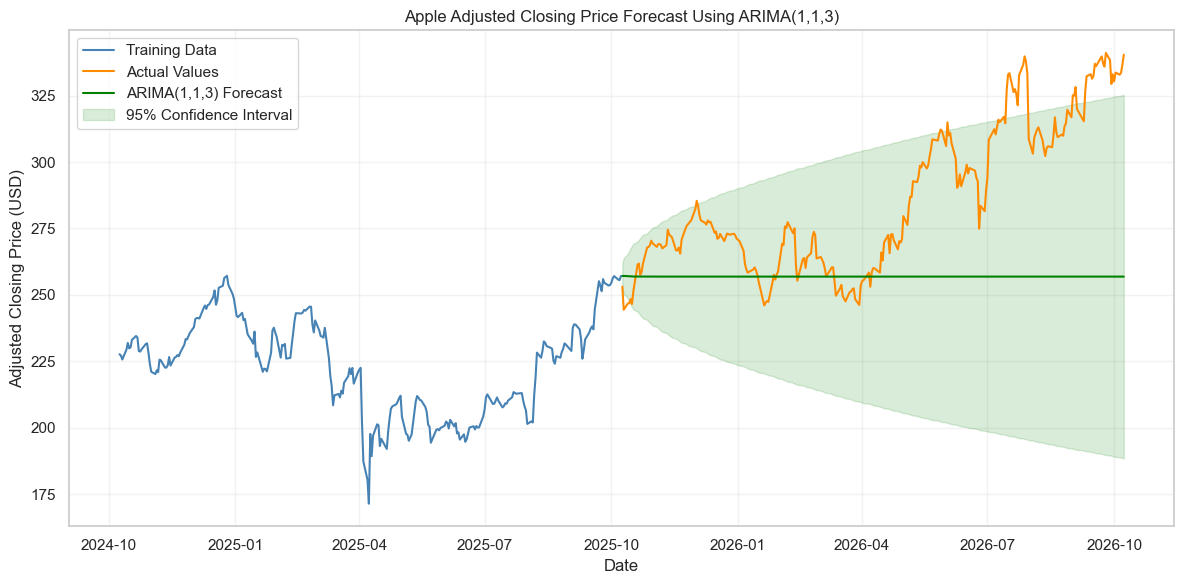

In [65]:
# Generate forecasts for the test period
forecast_result = final_arima_fit.get_forecast(
    steps=len(test_series)
)

# Extract forecast values
arima_forecast = pd.Series(
    forecast_result.predicted_mean,
    index=test_series.index,
    name="ARIMA_Forecast"
)

# Extract the 95% confidence interval
confidence_interval = np.asarray(
    forecast_result.conf_int(alpha=0.05)
)

lower_confidence = pd.Series(
    confidence_interval[:, 0],
    index=test_series.index
)

upper_confidence = pd.Series(
    confidence_interval[:, 1],
    index=test_series.index
)

# Plot the actual and forecast values
plt.figure(figsize=(12, 6))

plt.plot(
    train_series.index[-250:],
    train_series.iloc[-250:],
    label="Training Data",
    color="steelblue"
)

plt.plot(
    test_series.index,
    test_series,
    label="Actual Values",
    color="darkorange"
)

plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA(1,1,3) Forecast",
    color="green"
)

plt.fill_between(
    test_series.index,
    lower_confidence,
    upper_confidence,
    color="green",
    alpha=0.15,
    label="95% Confidence Interval"
)

plt.title("Apple Adjusted Closing Price Forecast Using ARIMA(1,1,3)")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [66]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
# Calculate ARIMA evaluation metrics
arima_mae = mean_absolute_error(
    test_series,
    arima_forecast
)

arima_rmse = np.sqrt(
    mean_squared_error(
        test_series,
        arima_forecast
    )
)

arima_mape = np.mean(
    np.abs(
        (test_series.to_numpy() - arima_forecast.to_numpy())
        / test_series.to_numpy()
    )
) * 100

# Create a table with the evaluation results
arima_metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE"],
    "Value": [arima_mae, arima_rmse, arima_mape]
})

arima_metrics.round(3)

,Metric,Value
0,MAE,30.379
1,RMSE,39.858
2,MAPE,9.904


The ARIMA(1,1,3) model showed weak forecasting performance for this dataset and forecast horizon. Its predictions remained almost constant and failed to capture the upward trend and price fluctuations observed during the test period. The model produced an MAE of USD 30.38, an RMSE of USD 39.86 and a MAPE of 9.90%. Although the percentage error was close to 10%, the graphical results demonstrate that the model had limited ability to predict the direction and  dynamics of Apple’s share price over a long forecast horizon.

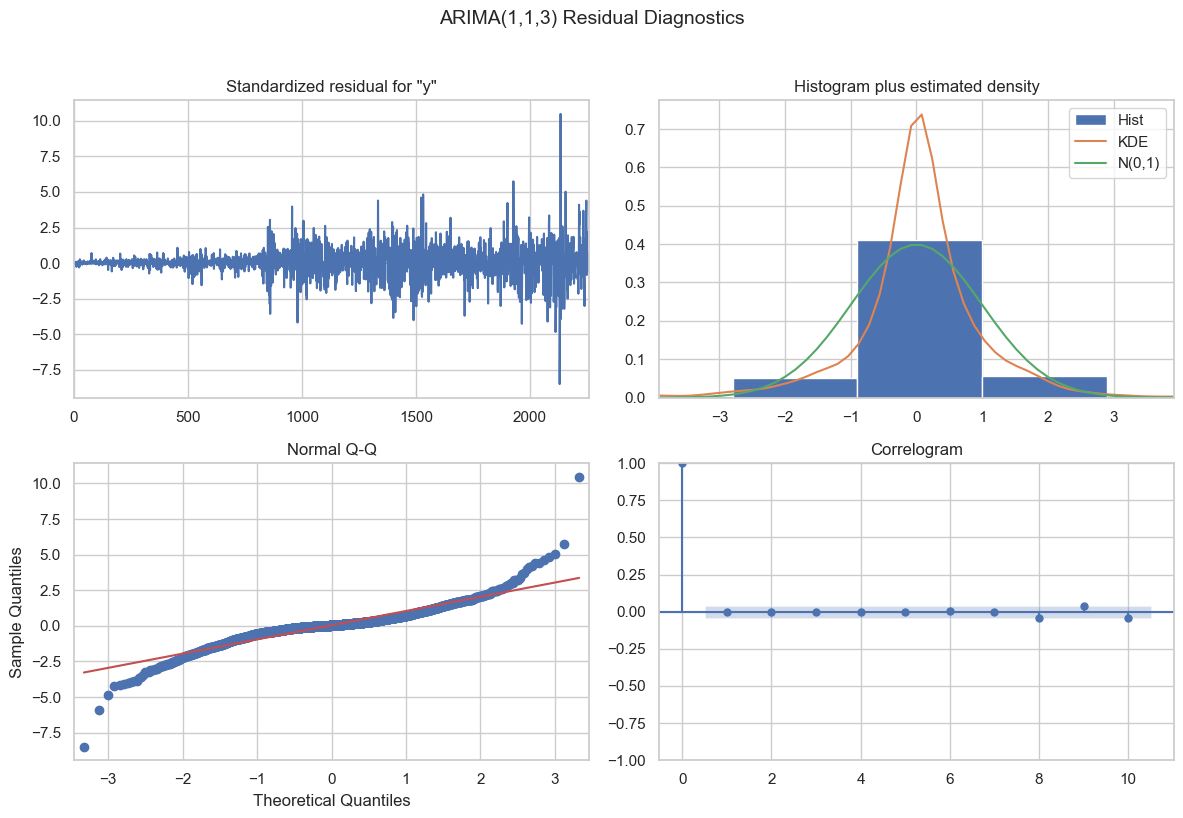

In [67]:
# Generate ARIMA residual diagnostic plots
final_arima_fit.plot_diagnostics(
    figsize=(12, 8)
)

plt.suptitle(
    "ARIMA(1,1,3) Residual Diagnostics",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

Diagnostic plots revealed that the residuals exhibit little autocorrelation, indicating that the model captured most of the linear temporal dependence in the series. However, the residuals show unstable variance, extreme values, and deviations from a normal distribution—findings that align with the results of the Jarque–Bera and heteroscedasticity tests. Furthermore, the forecasts generated by the ARIMA(1,1,3) model remained virtually constant, failing to capture either the upward trend or the price fluctuations observed during the test period. The model yielded an MAE of 30.38 USD, an RMSE of 39.86 USD, and a MAPE of 9.90%. These results suggest that, while the model estimated the general price level reasonably well, it demonstrated limited capacity to predict long-term shifts or sudden market movements. As a univariate model, ARIMA also falls short by failing to incorporate external factors, such as corporate announcements, economic conditions, or investor behavior.

Selection and application of the SARIMA model

SARIMA will be applied as an additional time series model to investigate whether a weekly trading pattern can improve forecasting. A seasonal period of five observations—representing the approximate number of trading days in a week—will be tested. As previous analysis did not provide robust evidence to justify seasonal differencing, the seasonal differencing parameter will initially be set to zero. Various combinations of seasonal parameters will be compared using the AIC and BIC criteria before the final SARIMA model is selected

In [68]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Seasonal parameter combinations
seasonal_candidates = [
    (1, 0, 0, 5),
    (0, 0, 1, 5),
    (1, 0, 1, 5)
]

sarima_results = []

# Use the same training data used for ARIMA
train_values = train_series.to_numpy()

# Fit each SARIMA candidate
for seasonal_order in seasonal_candidates:
    try:
        sarima_model = SARIMAX(
            train_values,
            order=(1, 1, 3),
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        sarima_fit = sarima_model.fit(
            disp=False
        )

        sarima_results.append({
            "Order": "(1,1,3)",
            "Seasonal_Order": str(seasonal_order),
            "AIC": sarima_fit.aic,
            "BIC": sarima_fit.bic
        })

    except Exception as error:
        print(
            f"SARIMA {seasonal_order} could not be fitted: {error}"
        )

# Create the comparison table
sarima_comparison = (
    pd.DataFrame(sarima_results)
    .sort_values("AIC")
    .reset_index(drop=True)
)

sarima_comparison.round(3)

,Order,Seasonal_Order,AIC,BIC
0,"(1,1,3)","(0, 0, 1, 5)",10388.753,10423.071
1,"(1,1,3)","(1, 0, 1, 5)",10390.677,10430.714
2,"(1,1,3)","(1, 0, 0, 5)",10399.578,10433.904


Three combinations of seasonal parameters were compared, while keeping the non-seasonal order at (1,1,3). The seasonal order (0,0,1,5) yielded the lowest AIC value (10388.756) and the lowest BIC value (10423.073). Therefore, the SARIMA(1,1,3)(0,0,1,5) model was selected for further forecasting and evaluation; however, its forecasting performance will still need to be assessed using test data before it can be compared to the ARIMA model.

In [69]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Fit the selected SARIMA model
final_sarima = SARIMAX(
    train_series.to_numpy(),
    order=(1, 1, 3),
    seasonal_order=(0, 0, 1, 5),
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_sarima_fit = final_sarima.fit(
    disp=False
)

print(final_sarima_fit.summary())

                                      SARIMAX Results                                      
Dep. Variable:                                   y   No. Observations:                 2262
Model:             SARIMAX(1, 1, 3)x(0, 0, [1], 5)   Log Likelihood               -5188.377
Date:                             Fri, 30 Oct 2026   AIC                          10388.753
Time:                                     01:31:40   BIC                          10423.071
Sample:                                          0   HQIC                         10401.278
                                            - 2262                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6362      0.163      3.915      0.000       0.318       0.955
ma.L1         -0.6242      

The selected SARIMA(1,1,3)(0,0,1,5) model was fitted using 2,262 training observations. The AR(1), MA(1), and MA(3) parameters yielded statistically significant results, whereas the MA(2) parameter was not significant at the 5% level. The seasonal MA(1) parameter showed a p-value of 0.995, indicating that the five-day seasonal component was not statistically significant. Residual diagnostics also indicated a lack of normality and unstable variance. Therefore, the model's forecasting performance will be evaluated on the test data before being compared to that of the ARIMA model.

In [70]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Generate SARIMA forecasts
sarima_forecast_result = final_sarima_fit.get_forecast(
    steps=len(test_series)
)

sarima_forecast = pd.Series(
    sarima_forecast_result.predicted_mean,
    index=test_series.index,
    name="SARIMA_Forecast"
)

# Calculate SARIMA evaluation metrics
sarima_mae = mean_absolute_error(
    test_series,
    sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(
        test_series,
        sarima_forecast
    )
)

sarima_mape = np.mean(
    np.abs(
        (test_series.to_numpy() - sarima_forecast.to_numpy())
        / test_series.to_numpy()
    )
) * 100

# Compare ARIMA and SARIMA metrics
model_comparison = pd.DataFrame({
    "Model": [
        "ARIMA(1,1,3)",
        "SARIMA(1,1,3)(0,0,1,5)"
    ],
    "MAE": [
        arima_mae,
        sarima_mae
    ],
    "RMSE": [
        arima_rmse,
        sarima_rmse
    ],
    "MAPE": [
        arima_mape,
        sarima_mape
    ]
})

model_comparison.round(3)



,Model,MAE,RMSE,MAPE
0,"ARIMA(1,1,3)",30.379,39.858,9.904
1,"SARIMA(1,1,3)(0,0,1,5)",30.348,39.827,9.893


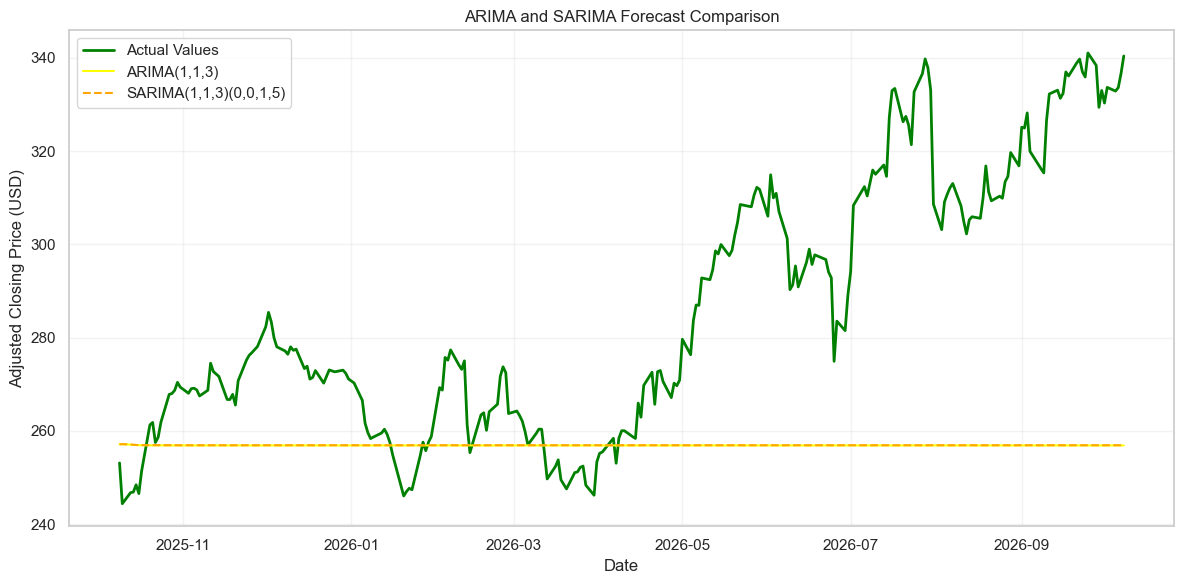

In [71]:
plt.figure(figsize=(12, 6))

plt.plot(
    test_series.index,
    test_series,
    label="Actual Values",
    color="green",
    linewidth=2
)

plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA(1,1,3)",
    color="yellow"
)

plt.plot(
    sarima_forecast.index,
    sarima_forecast,
    label="SARIMA(1,1,3)(0,0,1,5)",
    color="orange",
    linestyle="--"
)

plt.title("ARIMA and SARIMA Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

The forecasts from the ARIMA and SARIMA models were virtually identical and remained nearly constant throughout the test period. Neither model adequately captured the upward trend or the fluctuations observed in the actual prices. The similarity between the forecasts is consistent with the SARIMA results, as the five-day seasonal component was not statistically significant. Consequently, incorporating this seasonality did not yield any meaningful visual improvement over the ARIMA model.

In [72]:
# Naive forecast: use the last training value for the entire test period
naive_forecast = pd.Series(
    train_series.iloc[-1],
    index=test_series.index,
    name="Naive_Forecast"
)

naive_mae = mean_absolute_error(test_series, naive_forecast)
naive_rmse = np.sqrt(mean_squared_error(test_series, naive_forecast))
naive_mape = (
    np.mean(
        np.abs(
            (test_series.to_numpy() - naive_forecast.to_numpy())
            / test_series.to_numpy()
        )
    ) * 100
)

final_model_comparison = pd.DataFrame({
    "Model": [
        "Naive Forecast",
        "ARIMA(1,1,3)",
        "SARIMA(1,1,3)(0,0,1,5)"
    ],
    "MAE": [
        naive_mae,
        arima_mae,
        sarima_mae
    ],
    "RMSE": [
        naive_rmse,
        arima_rmse,
        sarima_rmse
    ],
    "MAPE": [
        naive_mape,
        arima_mape,
        sarima_mape
    ]
})

final_model_comparison.round(3)

,Model,MAE,RMSE,MAPE
0,Naive Forecast,30.197,39.683,9.842
1,"ARIMA(1,1,3)",30.379,39.858,9.904
2,"SARIMA(1,1,3)(0,0,1,5)",30.348,39.827,9.893


The Naive Forecast yielded the lowest MAE, RMSE, and MAPE values, slightly outperforming the ARIMA and SARIMA models. SARIMA produced marginally better results than ARIMA, but the differences between the two models were very small and do not represent a significant practical improvement. This result is consistent with the non-significant seasonal parameter in the SARIMA model and the overlap in forecasts observed in the chart. Therefore, the inclusion of a five-day seasonal component did not meaningfully enhance the model's predictive capability. Although all three models showed a MAPE close to 10%, none of them adequately captured the upward trend or the price fluctuations during the test period. The superior performance of the Naive model demonstrates that the greater complexity of the ARIMA and SARIMA models did not lead to more accurate forecasts for this time horizon.

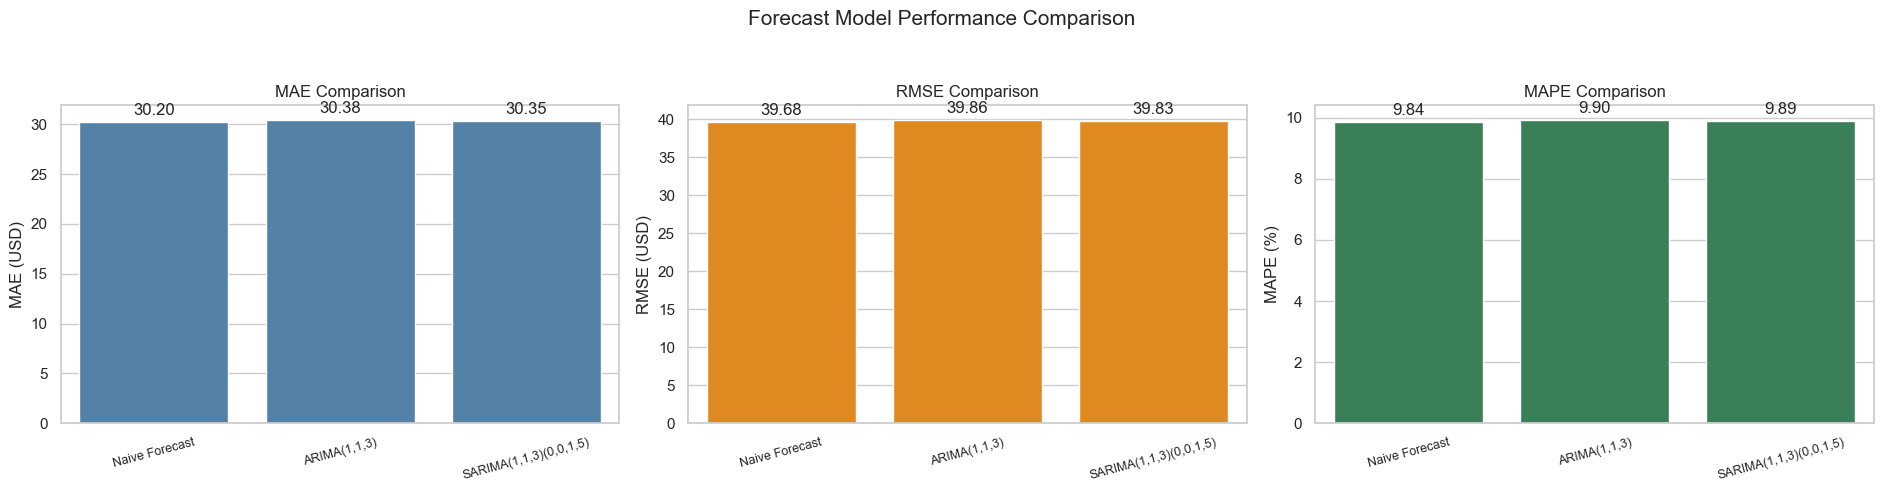

In [73]:
# Create three charts side by side
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

metrics = ["MAE", "RMSE", "MAPE"]
colours = ["steelblue", "darkorange", "seagreen"]

# Correct measurement unit for each metric
y_labels = {
    "MAE": "MAE (USD)",
    "RMSE": "RMSE (USD)",
    "MAPE": "MAPE (%)"
}

for ax, metric, colour in zip(axes, metrics, colours):
    
    sns.barplot(
        data=final_model_comparison,
        x="Model",
        y=metric,
        color=colour,
        ax=ax
    )

    ax.set_title(f"{metric} Comparison")
    ax.set_xlabel("")
    ax.set_ylabel(y_labels[metric])
    ax.tick_params(axis="x", rotation=15, labelsize=9)

    # Display the values above the bars
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.2f",
            padding=3
        )

# Main title
plt.suptitle(
    "Forecast Model Performance Comparison",
    fontsize=15
)

# Adjust spacing between the title and charts
plt.tight_layout(rect=[0, 0, 1, 0.94])

plt.show()

Overall Conclusion
This project analysed ten years of Apple stock market data using clustering and time-series forecasting techniques. Following feature engineering, RobustScaler and PCA (Principal Component Analysis) were applied to prepare the trading indicators for unsupervised learning. Four principal components were retained, preserving approximately 95.46% of the total variance.

The K-Means algorithm identified three interpretable market regimes: Stable Market, Positive High Activity and Negative High Activity. Although DBSCAN achieved a higher Silhouette Score and a lower Davies–Bouldin Index, it assigned 98.60% of the observations to a single dominant cluster. Consequently, K-Means was more useful for interpreting distinct market conditions, whereas DBSCAN was better suited to detecting atypical observations.

In the time-series analysis, the original adjusted closing-price series was found to be non-stationary, requiring first-order differencing. The ARIMA and SARIMA models produced very similar forecasts, and the five-day seasonal component was not statistically significant. The Naive Forecast yielded slightly lower MAE, RMSE and MAPE values than the two statistical models. None of the models adequately captured the upward trend or the price fluctuations observed during the test period.

Overall, the analysis demonstrated that clustering was useful for describing historical market regimes; however, forecasting future stock-price movements remained challenging. These results should be interpreted with caution, as the models relied solely on historical market data and excluded external factors such as economic conditions, company announcements and investor behaviour.

## References

Yahoo Finance (2026) *Apple Inc. (AAPL) historical stock data*. Yahoo Finance. Available at: https://finance.yahoo.com/quote/AAPL/history/ (Accessed: 29 October 2026).

Box, G.E.P., Jenkins, G.M., Reinsel, G.C. and Ljung, G.M. (2015) *Time Series Analysis: Forecasting and Control*. 5th edn. Hoboken, NJ: John Wiley & Sons.

Davies, D.L. and Bouldin, D.W. (1979) ‘A cluster separation measure’, *IEEE Transactions on Pattern Analysis and Machine Intelligence*, PAMI-1(2), pp. 224–227. Available at: https://doi.org/10.1109/TPAMI.1979.4766909.

Dickey, D.A. and Fuller, W.A. (1979) ‘Distribution of the estimators for autoregressive time series with a unit root’, *Journal of the American Statistical Association*, 74(366), pp. 427–431. Available at: https://doi.org/10.1080/01621459.1979.10482531.

Ester, M., Kriegel, H.-P., Sander, J. and Xu, X. (1996) ‘A density-based algorithm for discovering clusters in large spatial databases with noise’, *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining*, pp. 226–231. Available at: https://www.aaai.org/Papers/KDD/1996/KDD96-037.pdf.

Harris, C.R. et al. (2020) ‘Array programming with NumPy’, *Nature*, 585, pp. 357–362. Available at: https://doi.org/10.1038/s41586-020-2649-2.

Hunter, J.D. (2007) ‘Matplotlib: A 2D graphics environment’, *Computing in Science & Engineering*, 9(3), pp. 90–95. Available at: https://doi.org/10.1109/MCSE.2007.55.

Hyndman, R.J. and Athanasopoulos, G. (2021) *Forecasting: Principles and Practice*. 3rd edn. Melbourne: OTexts. Available at: https://otexts.com/fpp3/ (Accessed: 29 October 2026).

Jarque, C.M. and Bera, A.K. (1987) ‘A test for normality of observations and regression residuals’, *International Statistical Review*, 55(2), pp. 163–172. Available at: https://doi.org/10.2307/1403192.

Ljung, G.M. and Box, G.E.P. (1978) ‘On a measure of lack of fit in time series models’, *Biometrika*, 65(2), pp. 297–303. Available at: https://doi.org/10.1093/biomet/65.2.297.

MacQueen, J. (1967) ‘Some methods for classification and analysis of multivariate observations’, *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability*, 1, pp. 281–297.

McKinney, W. (2010) ‘Data structures for statistical computing in Python’, *Proceedings of the 9th Python in Science Conference*, pp. 56–61. Available at: https://doi.org/10.25080/Majora-92bf1922-00a.

Pearson, K. (1901) ‘On lines and planes of closest fit to systems of points in space’, *Philosophical Magazine*, 2(11), pp. 559–572. Available at: https://doi.org/10.1080/14786440109462720.

Pedregosa, F. et al. (2011) ‘Scikit-learn: Machine learning in Python’, *Journal of Machine Learning Research*, 12, pp. 2825–2830. Available at: https://jmlr.org/papers/v12/pedregosa11a.html.

Rousseeuw, P.J. (1987) ‘Silhouettes: A graphical aid to the interpretation and validation of cluster analysis’, *Journal of Computational and Applied Mathematics*, 20, pp. 53–65. Available at: https://doi.org/10.1016/0377-0427(87)90125-7.

Seabold, S. and Perktold, J. (2010) ‘Statsmodels: Econometric and statistical modeling with Python’, *Proceedings of the 9th Python in Science Conference*, pp. 92–96. Available at: https://doi.org/10.25080/Majora-92bf1922-011.

Waskom, M.L. (2021) ‘Seaborn: Statistical data visualization’, *Journal of Open Source Software*, 6(60), p. 3021. Available at: https://doi.org/10.21105/joss.03021.